# Clustering Non Supervisé — Pipeline Complet

Ce notebook couvre les algorithmes de clustering, leur évaluation, et leur application sur notre jeu de données de témoignages médicaux (`Student_Dataset.csv`).

## 1. Import des bibliotheques

On importe les outils necessaires :
- **numpy / pandas** : manipulation de donnees
- **matplotlib / seaborn** : visualisation
- **scikit-learn** : KMeans, Agglomerative, TF-IDF, SVD, metriques (silhouette, Calinski-Harabasz, Davies-Bouldin)
- **hdbscan** (optionnel) : clustering par densite hierarchique

In [2]:
import os, csv, warnings, itertools, re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score)
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestCentroid

import nltk
from nltk.stem import WordNetLemmatizer
nltk.download('punkt_tab', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('stopwords', quiet=True)

try:
    import hdbscan as _hdbscan
    HAS_HDBSCAN = True
except ImportError:
    HAS_HDBSCAN = False
    _hdbscan = None

try:
    import umap as _umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    _umap = None

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

def find_project_root(start_dir, target_file='Student_Dataset.csv', max_depth=6):
    current = os.path.abspath(start_dir)
    for _ in range(max_depth + 1):
        candidate = os.path.join(current, target_file)
        if os.path.isfile(candidate):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent
    return os.path.abspath(start_dir)

PROJECT_ROOT = find_project_root(os.getcwd())
DATASET_PATH = os.path.join(PROJECT_ROOT, 'Student_Dataset.csv')

print('Imports OK')
print(f'PROJECT_ROOT: {PROJECT_ROOT}')
print(f'DATASET_PATH: {DATASET_PATH}')
print(f'CSV found: {os.path.exists(DATASET_PATH)}')
print(f'HDBSCAN: {HAS_HDBSCAN}')
print(f'UMAP: {HAS_UMAP}')

/home/nathan-muzay/A_tek/S3/AIA/CVRIE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK
PROJECT_ROOT: /home/nathan-muzay/A_tek/S3/AIA/CVRIE
DATASET_PATH: /home/nathan-muzay/A_tek/S3/AIA/CVRIE/Student_Dataset.csv
CSV found: True
HDBSCAN: True
UMAP: True


---

## 2. Pipeline de traitement

On applique le pipeline complet sur le dataset `Student_Dataset.csv` de témoignages médicaux :

1. **Nettoyage** : correction orthographique, suppression des stop-words médicaux, lemmatisation
2. **Vectorisation** : transformation du texte en vecteurs numériques (TF-IDF)
3. **Clustering** : deux stratégies sont testées et comparées automatiquement

L'objectif est de regrouper les témoignages en clusters thématiques cohérents (ex: symptômes respiratoires, douleurs articulaires, etc.).

### 2.1 Chargement et nettoyage du CSV

Lecture directe de `Student_Dataset.csv`, puis nettoyage local :
- **Normalisation** : passage en minuscules et suppression de la ponctuation
- **Tokenisation et lemmatisation** avec NLTK (`WordNetLemmatizer`)
- **Suppression des stop-words** avec conservation des intensifieurs utiles (`very`, `more`, `less`)
- **Ban words metier** : exclusion explicite de termes peu discriminants (`doctor`, `get`, `make`, `start`, `short`, `new`, `side`, `deep`, `give`, `raised`, `feel`, `also`, `felt`, `pause`, `small`, `touched`, `not`, `appeared`, `appear`, `around`, `area`, `friction`, `along`, `brings`, `day`, `no`, `lunch`, `high`, `look`, `notice`, `stand`, `keep`, `across`, `light`, `lying`, `outer`)

In [3]:
# Lire le CSV brut directement depuis la racine du projet
df_raw = pd.read_csv(
    DATASET_PATH,
    header=None,
    names=['doc_id', 'label', 'text'],
    encoding='utf-8-sig',
)
df_raw = df_raw.dropna(subset=['text']).reset_index(drop=True)

doc_ids = df_raw['doc_id'].astype(str).tolist()
raw_texts = df_raw['text'].astype(str).tolist()
raw_rows = df_raw[['doc_id', 'label', 'text']].values.tolist()

print(f'Lignes brutes : {len(raw_rows)}')
print(f'Exemple (ligne 1) : {raw_rows[0]}')

Lignes brutes : 1011
Exemple (ligne 1) : [1, '0x000000', 'On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.']


In [4]:
# Nettoyage local pour eviter toute dependance externe (src/unsupervised)
lemmatizer = WordNetLemmatizer()
stop_words = set(nltk.corpus.stopwords.words('english'))
keep_words = {'very', 'more', 'less'}
stop_words = stop_words - keep_words

# Ban words explicites demandes pour reduire les termes non discriminants.
ban_words = {
    'doctor', 'get', 'make', 'start', 'short', 'new', 'side',
    'deep', 'give', 'raised', 'feel', 'felt', 'also', 'pause',
    'small', 'touched', 'not', 'appeared', 'appear', 'around',
    'area', 'friction', 'along', 'brings', 'bring', 'day', 'no',
    'lunch', 'high', 'look', 'notice', 'stand', 'keep', 'across',
    'light', 'lying', 'outer',
}

def simple_clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s']", ' ', text)
    tokens = nltk.word_tokenize(text)
    kept = []
    for tok in tokens:
        if not tok.isalpha() or tok in stop_words or len(tok) <= 1:
            continue
        lemma = lemmatizer.lemmatize(tok)
        # Double filtre ban words: avant et apres lemmatisation.
        if tok in ban_words or lemma in ban_words:
            continue
        kept.append(lemma)
    return ' '.join(kept)

cleaned = []
cleaned_doc_ids = []
for did, txt in zip(doc_ids, raw_texts):
    if txt and txt.strip():
        cleaned.append(simple_clean_text(txt))
        cleaned_doc_ids.append(did)

doc_ids = cleaned_doc_ids

print(f'Ban words actives : {sorted(ban_words)}')
print(f'Documents nettoyes : {len(cleaned)}')
print(f'\nAvant : {raw_texts[0]}')
print(f'Apres : {cleaned[0]}')

Ban words actives : ['across', 'along', 'also', 'appear', 'appeared', 'area', 'around', 'bring', 'brings', 'day', 'deep', 'doctor', 'feel', 'felt', 'friction', 'get', 'give', 'high', 'keep', 'light', 'look', 'lunch', 'lying', 'make', 'new', 'no', 'not', 'notice', 'outer', 'pause', 'raised', 'short', 'side', 'small', 'stand', 'start', 'touched']
Documents nettoyes : 1011

Avant : On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.
Apres : uneven path heel wobbly slanted pavement quick aching shift ankle step


### 2.2 Vectorisation TF-IDF

**TF-IDF** transforme chaque document en un vecteur numérique :
- `sublinear_tf=True` : atténue les termes très fréquents via `1 + log(TF)`
- `ngram_range=(1, 2)` : unigrammes + bigrammes (ex: "chest pain")
- `min_df=2, max_df=0.70` : filtre les termes trop rares ou trop communs
- `norm='l2'` : normalisation pour que chaque document ait la même norme

In [5]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.70,
    sublinear_tf=True,
    norm='l2',
)
X_tfidf = vectorizer.fit_transform(cleaned)
print(X_tfidf)
vocab = vectorizer.get_feature_names_out()

print(f'Matrice TF-IDF : {X_tfidf.shape[0]} docs × {X_tfidf.shape[1]} termes')

# Top 20 termes
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).flatten()
top_idx = mean_tfidf.argsort()[::-1][:20]
print('\nTop 20 termes par score TF-IDF moyen :')
for rank, idx in enumerate(top_idx, 1):
    print(f'  {rank:2d}. {vocab[idx]:<25s} {mean_tfidf[idx]:.4f}')

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16629 stored elements and shape (1011, 2812)>
  Coords	Values
  (0, 2606)	0.21309533844153705
  (0, 1662)	0.26000072389218365
  (0, 1034)	0.21309533844153705
  (0, 2774)	0.22772919873574365
  (0, 2078)	0.27144922963599694
  (0, 1665)	0.26000072389218365
  (0, 1776)	0.19401039819077912
  (0, 31)	0.2377304290910324
  (0, 2003)	0.2324164555701503
  (0, 51)	0.17724791892608371
  (0, 2249)	0.1811654092633129
  (0, 2609)	0.26000072389218365
  (0, 1663)	0.27144922963599694
  (0, 1035)	0.27144922963599694
  (0, 2079)	0.27144922963599694
  (0, 1666)	0.27144922963599694
  (0, 2004)	0.27144922963599694
  (1, 786)	0.26578860963897954
  (1, 764)	0.16579322680048522
  (1, 656)	0.2973336407652669
  (1, 262)	0.21214818580184344
  (1, 757)	0.28717840899161867
  (1, 622)	0.1999395293367693
  (1, 488)	0.15877785094717659
  (1, 1007)	0.2556333778653313
  :	:
  (1009, 357)	0.2515316182647089
  (1009, 275)	0.23279688516127503
  (1009, 276)	0.2381

In [6]:
# Verification rapide: presence des ban words dans le vocabulaire
vocab_set = set(vectorizer.get_feature_names_out())
present_ban_words = sorted([w for w in ban_words if w in vocab_set])
print(f'Ban words encore presentes dans le vocabulaire: {present_ban_words}')
print('OK' if len(present_ban_words) == 0 else 'Attention: certaines ban words subsistent.')

Ban words encore presentes dans le vocabulaire: []
OK


## 3. Strategie A — TF-IDF + SVD + K-Means (optimisee)

1. **Recherche de `n_components` (SVD)** : on teste plusieurs dimensions latentes pour maximiser la separabilite
2. **Normalisation L2** : distances plus stables en clustering
3. **Recherche de `K` + hyperparametres KMeans** : selection par score composite (Silhouette + Davies-Bouldin)

In [7]:
# Optimisation SVD + KMeans (Strategie A)
n_docs, n_terms = X_tfidf.shape
max_svd = max(2, min(n_docs - 1, n_terms - 1))

raw_candidates = [64, 96, 128, 160, 192, 256, 320]
svd_candidates = sorted({c for c in raw_candidates if c <= max_svd})
if len(svd_candidates) == 0:
    svd_candidates = [max_svd]

# On diminue volontairement le nombre de clusters explores pour eviter un K trop eleve.
k_min = 3
k_max = 15
k_search = list(range(k_min, k_max + 1))
TARGET_A_MIN = 6
TARGET_A_MAX = 10
min_cluster_size_target = max(8, int(0.010 * n_docs))

search_rows_a = []
best_cfg_a = None
best_score_a = -1e9

print(f'Grille SVD testee : {svd_candidates}')
print(f'Grille K testee   : {k_search}')

for n_comp in svd_candidates:
    svd_try = TruncatedSVD(n_components=n_comp, random_state=42)
    X_svd_try = svd_try.fit_transform(X_tfidf)
    X_svd_try = Normalizer(norm='l2').fit_transform(X_svd_try)
    explained = float(svd_try.explained_variance_ratio_.sum())

    for k in k_search:
        km = KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=60,
            max_iter=1000,
            tol=1e-4,
            algorithm='lloyd',
            random_state=42,
        )
        labels_try = km.fit_predict(X_svd_try)

        sil = silhouette_score(X_svd_try, labels_try, metric='euclidean')
        db = davies_bouldin_score(X_svd_try, labels_try)
        ch = calinski_harabasz_score(X_svd_try, labels_try)

        sizes = np.array([(labels_try == c).sum() for c in sorted(set(labels_try))], dtype=float)
        tiny_ratio = float((sizes < min_cluster_size_target).mean())
        imbalance = float(sizes.std() / max(sizes.mean(), 1.0))

        if k < TARGET_A_MIN:
            k_target_penalty = 0.035 * (TARGET_A_MIN - k)
        elif k > TARGET_A_MAX:
            k_target_penalty = 0.050 * (k - TARGET_A_MAX)
        else:
            k_target_penalty = -0.020

        # Score composite: separation + compacite, avec forte penalisation des K trop grands.
        rank = (
            1.20 * sil
            - 0.080 * db
            + 0.000015 * ch
            - 0.0040 * k
            + 0.025 * explained
            - 0.080 * tiny_ratio
            - 0.050 * imbalance
            - k_target_penalty
        )

        row = {
            'n_components': int(n_comp),
            'k': int(k),
            'explained_var': float(explained),
            'sil': float(sil),
            'db': float(db),
            'ch': float(ch),
            'tiny_ratio': float(tiny_ratio),
            'imbalance': float(imbalance),
            'k_target_penalty': float(k_target_penalty),
            'inertia': float(km.inertia_),
            'rank': float(rank),
        }
        search_rows_a.append(row)

        if rank > best_score_a:
            best_score_a = rank
            best_cfg_a = row

# Refit final sur la meilleure configuration
n_components = int(best_cfg_a['n_components'])
best_k_a = int(best_cfg_a['k'])

svd = TruncatedSVD(n_components=n_components, random_state=42)
X_svd = svd.fit_transform(X_tfidf)
X_svd = Normalizer(norm='l2').fit_transform(X_svd)

df_a_search = pd.DataFrame(search_rows_a).sort_values('rank', ascending=False).reset_index(drop=True)

print(f'\nMeilleure config A : n_components={n_components}, K={best_k_a}')
print(f"Silhouette={best_cfg_a['sil']:.3f} | DB={best_cfg_a['db']:.3f} | CH={best_cfg_a['ch']:.1f}")
print(f"Variance expliquee (SVD) : {svd.explained_variance_ratio_.sum():.2%}")
display(df_a_search.head(12))

Grille SVD testee : [64, 96, 128, 160, 192, 256, 320]
Grille K testee   : [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

Meilleure config A : n_components=64, K=10
Silhouette=0.070 | DB=3.349 | CH=24.1
Variance expliquee (SVD) : 24.23%


,n_components,k,explained_var,sil,db,ch,tiny_ratio,imbalance,k_target_penalty,inertia,rank
0,64,10,0.242300,0.070325,3.349343,24.122504,0.0,0.437845,-0.02,780.566679,-0.219030
1,64,9,0.242300,0.068197,3.447685,24.691350,0.0,0.407599,-0.02,793.443661,-0.223931
2,64,8,0.242300,0.065319,3.577451,25.508278,0.0,0.266084,-0.02,806.316756,-0.226677
3,64,7,0.242300,0.060771,3.604644,26.321081,0.0,0.453587,-0.02,820.757462,-0.239673
4,64,6,0.242300,0.054639,3.781010,27.297520,0.0,0.577599,-0.02,836.285646,-0.263328
5,64,11,0.242300,0.074424,3.278150,23.475702,0.0,0.408172,0.05,769.269078,-0.280942
6,96,10,0.321492,0.052303,4.002254,17.614459,0.0,0.386882,-0.02,832.919923,-0.288459
7,96,9,0.321492,0.051187,4.162803,18.119349,0.0,0.400341,-0.02,842.893362,-0.299308
8,96,7,0.321492,0.044661,4.248217,19.238287,0.0,0.462202,-0.02,865.342614,-0.309049
9,64,12,0.242300,0.079018,3.140772,23.065134,0.0,0.331606,0.10,757.482281,-0.314617


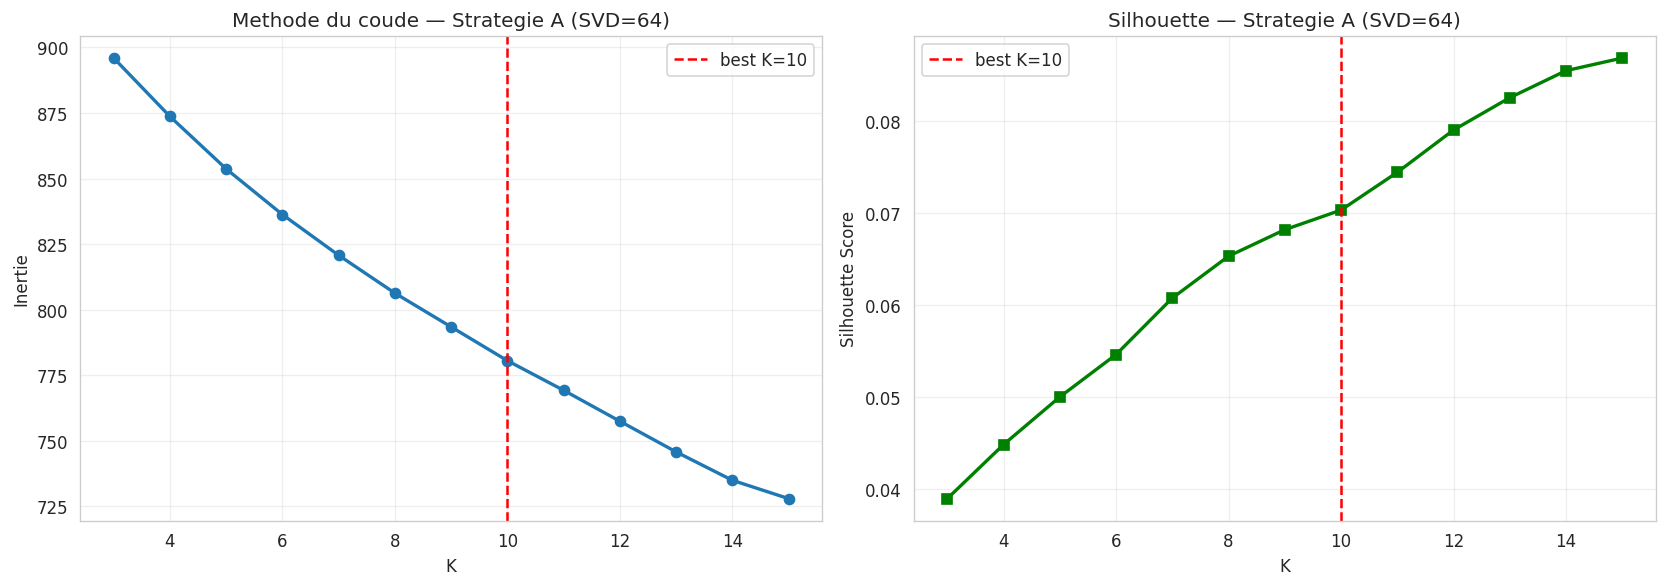

In [8]:
# Courbes de diagnostic autour de la meilleure dimension SVD
best_dim_rows = df_a_search[df_a_search['n_components'] == n_components].sort_values('k')

K_search = best_dim_rows['k'].tolist()
inertias_a = best_dim_rows['inertia'].tolist()
sil_scores_a = best_dim_rows['sil'].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_search, inertias_a, 'o-', linewidth=2)
axes[0].axvline(best_k_a, color='red', linestyle='--', label=f'best K={best_k_a}')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertie')
axes[0].set_title(f'Methode du coude — Strategie A (SVD={n_components})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_search, sil_scores_a, 's-', linewidth=2, color='green')
axes[1].axvline(best_k_a, color='red', linestyle='--', label=f'best K={best_k_a}')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title(f'Silhouette — Strategie A (SVD={n_components})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

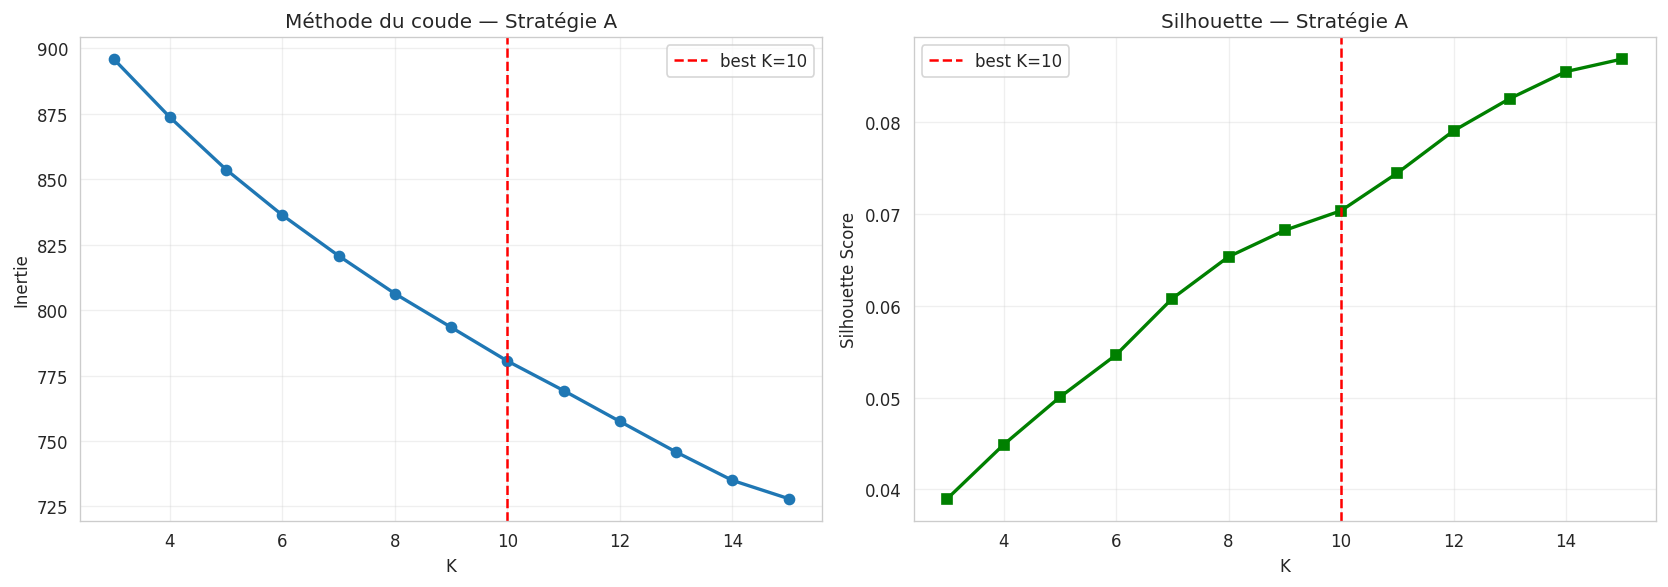

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_search), inertias_a, 'o-', linewidth=2)
axes[0].axvline(best_k_a, color='red', linestyle='--', label=f'best K={best_k_a}')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertie')
axes[0].set_title('Méthode du coude — Stratégie A')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(K_search), sil_scores_a, 's-', linewidth=2, color='green')
axes[1].axvline(best_k_a, color='red', linestyle='--', label=f'best K={best_k_a}')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette — Stratégie A')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Clustering final Stratégie A
km_final_a = KMeans(n_clusters=best_k_a, n_init=10, max_iter=300, random_state=42)
labels_a = km_final_a.fit_predict(X_svd)

sil_a = silhouette_score(X_svd, labels_a)
db_a = davies_bouldin_score(X_svd, labels_a)

print(f'Stratégie A — K={best_k_a}')
print(f'  Silhouette     : {sil_a:.3f}')
print(f'  Davies-Bouldin : {db_a:.3f}')
print(f'\nTaille des clusters :')
for cid in sorted(set(labels_a)):
    print(f'  Cluster {cid}: {(labels_a == cid).sum()} docs')

Stratégie A — K=10
  Silhouette     : 0.072
  Davies-Bouldin : 3.514

Taille des clusters :
  Cluster 0: 127 docs
  Cluster 1: 133 docs
  Cluster 2: 48 docs
  Cluster 3: 80 docs
  Cluster 4: 82 docs
  Cluster 5: 133 docs
  Cluster 6: 71 docs
  Cluster 7: 159 docs
  Cluster 8: 76 docs
  Cluster 9: 102 docs


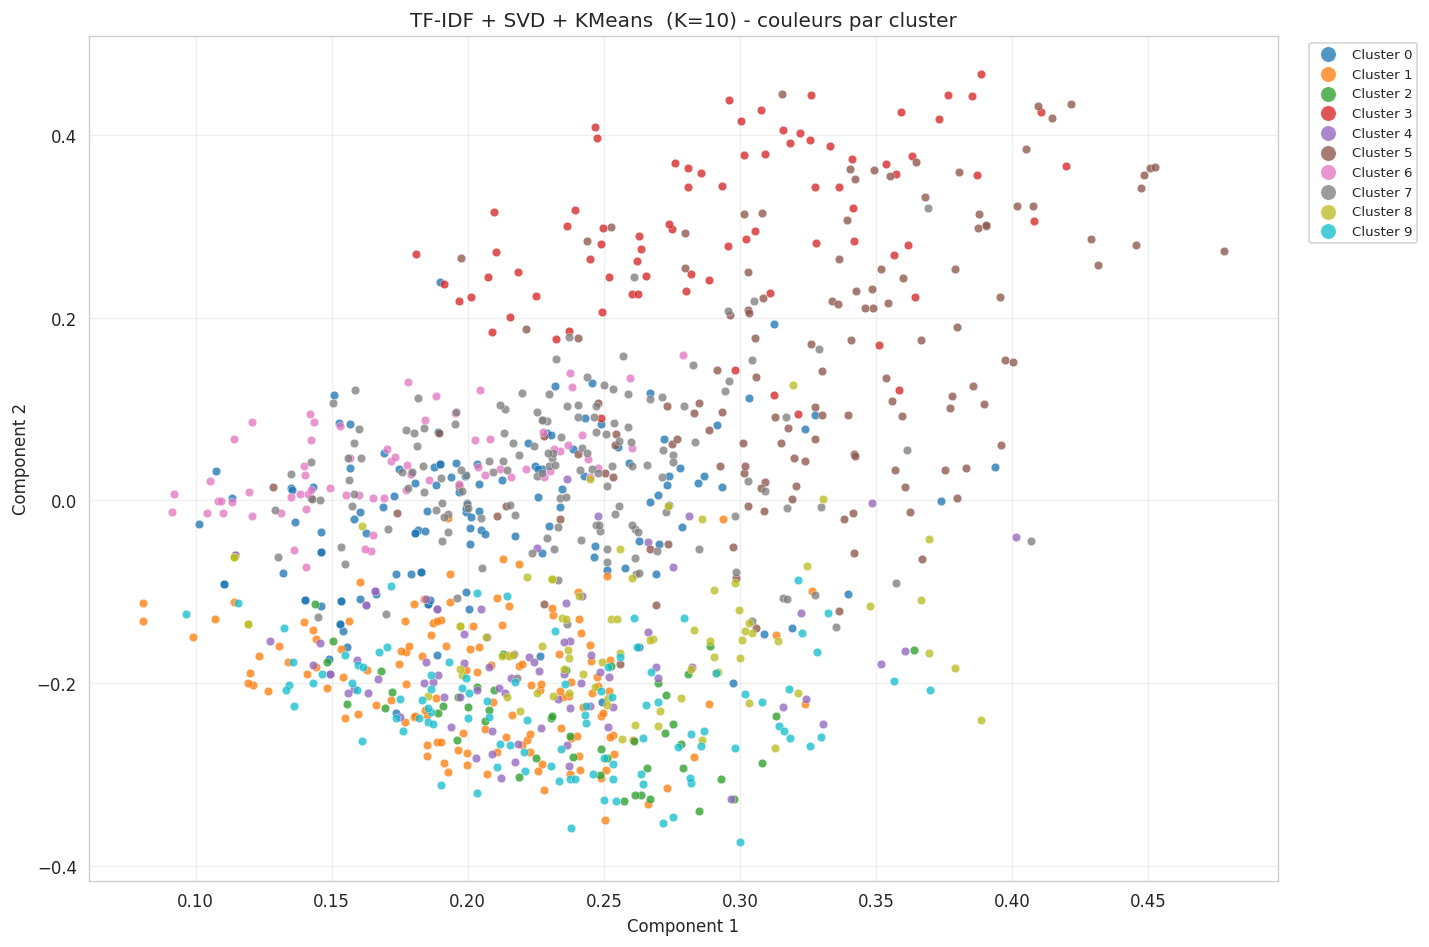

In [11]:
# Visuel type cellule 26, mais pour la Strategie A (KMeans sur SVD)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'labels_a' not in globals() or 'X_svd' not in globals():
    print("labels_a ou X_svd n'est pas defini. Execute d'abord les cellules de la Strategie A.")
else:
    X_2d_a = X_svd[:, :2]
    unique_labels_a = sorted(set(labels_a))

    palette = sns.color_palette('tab10', max(len(unique_labels_a), 1))
    color_map_a = {cid: palette[i % len(palette)] for i, cid in enumerate(unique_labels_a)}

    fig, ax = plt.subplots(figsize=(12, 8))
    for cid in unique_labels_a:
        m = labels_a == cid
        ax.scatter(
            X_2d_a[m, 0],
            X_2d_a[m, 1],
            c=[color_map_a[cid]],
            s=26,
            alpha=0.78,
            label=f'Cluster {cid}',
            edgecolors='white',
            linewidths=0.25,
        )

    k_val = globals().get('best_k_a', len(unique_labels_a))
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
    ax.set_title(f'TF-IDF + SVD + KMeans  (K={k_val}) - couleurs par cluster')
    ax.legend(fontsize=8, markerscale=1.8, loc='upper left', bbox_to_anchor=(1.02, 1.0))
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 4. Strategie B — TF-IDF + UMAP + HDBSCAN (cible 10-14 clusters)

1. **TF-IDF + UMAP** : espace non-lineaire plus separable pour le clustering de texte
2. **HDBSCAN** : clustering par densite hierarchique, avec controle de la plage de clusters
3. **Recherche de grille ciblee** : optimisation sur `min_cluster_size`, `min_samples` et `cluster_selection_epsilon`

Cette strategie vise des clusters plus distincts, avec une tolerance a un certain niveau de bruit (`-1`) pour limiter le chevauchement.

In [12]:
features_b = None
features_b_vis = None
features_b_name = None

if HAS_HDBSCAN:
    if HAS_UMAP:
        # Regime plus separatif: voisinage plus local + spread plus large.
        n_neighbors_clust = min(28, max(8, int(np.sqrt(len(cleaned)) * 0.95)))
        n_neighbors_vis = min(22, max(6, int(np.sqrt(len(cleaned)) * 0.85)))

        umap_clust = _umap.UMAP(
            n_components=16,
            n_neighbors=n_neighbors_clust,
            min_dist=0.0,
            spread=2.4,
            metric='cosine',
            random_state=42,
        )
        features_b = umap_clust.fit_transform(X_tfidf)

        # UMAP de visualisation projete depuis l'espace de clustering pour mieux respecter la separation.
        umap_vis = _umap.UMAP(
            n_components=2,
            n_neighbors=n_neighbors_vis,
            min_dist=0.0,
            spread=3.0,
            metric='euclidean',
            random_state=42,
        )
        features_b_vis = umap_vis.fit_transform(features_b)
        features_b_name = 'UMAP-separation(TF-IDF)'

        print('Strategie B: UMAP-separation + HDBSCAN')
        print(f'Features clustering : {features_b.shape} | Features visuelles : {features_b_vis.shape}')
    else:
        features_b = X_svd
        features_b_vis = X_svd[:, :2]
        features_b_name = 'SVD(TF-IDF)'
        print('UMAP non disponible -> fallback SVD + HDBSCAN')
        print(f'Features B : {features_b.shape}')
else:
    print('HDBSCAN non disponible — Strategie B ignoree')

Strategie B: UMAP-separation + HDBSCAN
Features clustering : (1011, 16) | Features visuelles : (1011, 2)


In [13]:
results_b = None
best_config = None

if features_b is not None:
    TARGET_CLUSTERS_MIN = 10
    TARGET_CLUSTERS_MAX = 14
    NOISE_TARGET_MAX = 0.12
    NOISE_HARD_MAX = 0.25

    max_cluster_cap = min(42, max(16, len(cleaned) // 2))
    min_cluster_grid = [3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 24, 28, 32]
    min_cluster_grid = [v for v in min_cluster_grid if v <= max_cluster_cap]
    if len(min_cluster_grid) == 0:
        min_cluster_grid = [4, 6, 8, 10]

    cfg = {
        'profile': 'hdbscan-targeted-separation',
        'target_clusters': (TARGET_CLUSTERS_MIN, TARGET_CLUSTERS_MAX),
        'hdbscan_min_cluster_grid': min_cluster_grid,
        'hdbscan_min_samples_grid': [1, 2, 3, 4, 5, None],
        'hdbscan_epsilon_grid': [0.00, 0.01, 0.02, 0.04, 0.06, 0.10],
        'max_configs': 320,
    }
    print(f"Profil adaptatif : {cfg['profile']} ({len(cleaned)} docs)")

    benchmark = []
    tested = 0
    combos = list(itertools.product(
        cfg['hdbscan_min_cluster_grid'],
        cfg['hdbscan_min_samples_grid'],
        cfg['hdbscan_epsilon_grid'],
    ))
    min_cluster_size_target = max(6, int(0.009 * len(cleaned)))

    best_target_low_noise = None
    best_target_low_noise_rank = -1e9
    best_target_any_noise = None
    best_target_any_noise_rank = -1e9
    best_global_config = None
    best_global_rank = -1e9

    for min_cluster, min_samp, eps in combos:
        if tested >= cfg['max_configs']:
            break
        tested += 1

        clusterer = _hdbscan.HDBSCAN(
            min_cluster_size=min_cluster,
            min_samples=min_samp,
            metric='euclidean',
            cluster_selection_method='eom',
            cluster_selection_epsilon=eps,
            prediction_data=True,
        )
        lbl = clusterer.fit_predict(features_b)

        n_cl = len(set(lbl) - {-1})
        n_noise = int((lbl == -1).sum())
        noise_ratio = n_noise / len(lbl)
        coverage = 1.0 - noise_ratio
        mask_v = lbl >= 0

        if n_cl >= 2 and mask_v.sum() > n_cl:
            Xv = features_b[mask_v]
            yv = lbl[mask_v]
            sil = silhouette_score(Xv, yv)
            ch = calinski_harabasz_score(Xv, yv)
            db = davies_bouldin_score(Xv, yv)

            unique_valid = sorted(set(yv))
            centers = np.vstack([Xv[yv == c].mean(axis=0) for c in unique_valid])
            center_d = pairwise_distances(centers, metric='euclidean')
            if center_d.shape[0] >= 2:
                center_d = center_d + np.eye(center_d.shape[0]) * 1e9
                min_center_dist = float(center_d.min())
            else:
                min_center_dist = 0.0

            within_vals = []
            for c in unique_valid:
                pts = Xv[yv == c]
                ctr = pts.mean(axis=0, keepdims=True)
                within_vals.append(float(np.linalg.norm(pts - ctr, axis=1).mean()))
            within_mean = float(np.mean(within_vals)) if len(within_vals) else 1.0
            separation_score = float(min_center_dist / max(within_mean, 1e-9))
            separation_score = float(np.clip(separation_score, 0.0, 8.0))
        else:
            sil = -1.0
            ch = 0.0
            db = 999.0
            separation_score = 0.0

        cluster_sizes = np.array([(lbl == c).sum() for c in set(lbl) if c >= 0], dtype=float)
        if len(cluster_sizes):
            tiny_ratio = float((cluster_sizes < min_cluster_size_target).mean())
            imbalance = float(cluster_sizes.std() / max(cluster_sizes.mean(), 1.0))
        else:
            tiny_ratio = 1.0
            imbalance = 1.0

        if n_cl < TARGET_CLUSTERS_MIN:
            cluster_target_penalty = 0.060 * (TARGET_CLUSTERS_MIN - n_cl)
        elif n_cl > TARGET_CLUSTERS_MAX:
            cluster_target_penalty = 0.045 * (n_cl - TARGET_CLUSTERS_MAX)
        else:
            cluster_target_penalty = -0.030

        rank = (
            1.25 * sil
            - 0.030 * db
            + 0.000020 * ch
            + 0.085 * separation_score
            - 0.055 * tiny_ratio
            - 0.050 * imbalance
            - 0.001 * n_cl
            - cluster_target_penalty
            + 0.005 * coverage
            - 0.22 * noise_ratio
        )

        row = {
            'min_cluster': int(min_cluster),
            'min_samp': min_samp,
            'eps': float(eps),
            'n_clusters': int(n_cl),
            'noise': int(n_noise),
            'sil': float(sil),
            'ch': float(ch),
            'db': float(db),
            'sep': float(separation_score),
            'noise_ratio': float(noise_ratio),
            'tiny_ratio': float(tiny_ratio),
            'imbalance': float(imbalance),
            'target_penalty': float(cluster_target_penalty),
            'rank': float(rank),
        }
        benchmark.append(row)

        in_target = TARGET_CLUSTERS_MIN <= n_cl <= TARGET_CLUSTERS_MAX
        if in_target and noise_ratio <= NOISE_TARGET_MAX and rank > best_target_low_noise_rank:
            best_target_low_noise_rank = rank
            best_target_low_noise = row
        if in_target and rank > best_target_any_noise_rank:
            best_target_any_noise_rank = rank
            best_target_any_noise = row
        if noise_ratio <= NOISE_HARD_MAX and rank > best_global_rank:
            best_global_rank = rank
            best_global_config = row

    if best_target_low_noise is not None:
        best_config = best_target_low_noise
        print(f'\nSelection ciblee + faible bruit: K dans [{TARGET_CLUSTERS_MIN}, {TARGET_CLUSTERS_MAX}] et bruit <= {NOISE_TARGET_MAX:.0%}.')
    elif best_target_any_noise is not None:
        best_config = best_target_any_noise
        print(f'\nSelection ciblee sans contrainte dure de bruit: K dans [{TARGET_CLUSTERS_MIN}, {TARGET_CLUSTERS_MAX}].')
    elif best_global_config is not None:
        best_config = best_global_config
        print(f'\nAucune config ciblee, fallback sur meilleur score global avec bruit <= {NOISE_HARD_MAX:.0%}.')
    else:
        df_tmp = pd.DataFrame(benchmark).sort_values('noise_ratio', ascending=True).reset_index(drop=True)
        best_config = df_tmp.iloc[0].to_dict()
        print('\nFallback ultime: selection de la config au bruit minimal.')

    df_bench = pd.DataFrame(benchmark).sort_values(['rank', 'noise_ratio'], ascending=[False, True]).reset_index(drop=True)
    print(f'Configs testees : {tested}')
    print(f'Meilleure config : {best_config}')
    display(df_bench.head(14))
else:
    print('Features de Strategie B non disponibles')

Profil adaptatif : hdbscan-targeted-separation (1011 docs)

Selection ciblee sans contrainte dure de bruit: K dans [10, 14].
Configs testees : 320
Meilleure config : {'min_cluster': 14, 'min_samp': 5, 'eps': 0.0, 'n_clusters': 14, 'noise': 295, 'sil': 0.505943238735199, 'ch': 1151.0661288689848, 'db': 0.6933745224369969, 'sep': 2.4990429611138087, 'noise_ratio': 0.29179030662710187, 'tiny_ratio': 0.0, 'imbalance': 0.45171147547618296, 'target_penalty': -0.03, 'rank': 0.7798293942530353}


,min_cluster,min_samp,eps,n_clusters,noise,sil,ch,db,sep,noise_ratio,tiny_ratio,imbalance,target_penalty,rank
0,14,5.0,0.00,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
1,14,5.0,0.01,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
2,14,5.0,0.02,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
3,14,5.0,0.04,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
4,14,5.0,0.06,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
5,14,5.0,0.10,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
6,16,5.0,0.00,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
7,16,5.0,0.01,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
8,16,5.0,0.02,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829
9,16,5.0,0.04,14,295,0.505943,1151.066129,0.693375,2.499043,0.29179,0.0,0.451711,-0.03,0.779829


In [14]:
# Fit final de la meilleure config sur tout le dataset (Strategie B)
if features_b is not None and best_config is not None:
    clusterer_best = _hdbscan.HDBSCAN(
        min_cluster_size=best_config['min_cluster'],
        min_samples=best_config['min_samp'],
        metric='euclidean',
        cluster_selection_method='eom',
        cluster_selection_epsilon=best_config['eps'],
        prediction_data=True,
    )
    labels_b_raw = clusterer_best.fit_predict(features_b)

    # Secours anti-degenerescence: relacher la config si HDBSCAN retourne trop de bruit.
    n_cl_raw = len(set(labels_b_raw) - {-1})
    noise_ratio_raw = float((labels_b_raw == -1).mean())
    if n_cl_raw < 2 or noise_ratio_raw > 0.88:
        print('HDBSCAN trop degenerate avec la config principale -> tentative de config plus permissive...')
        relaxed = _hdbscan.HDBSCAN(
            min_cluster_size=max(3, best_config['min_cluster'] // 2),
            min_samples=1,
            metric='euclidean',
            cluster_selection_method='eom',
            cluster_selection_epsilon=max(0.10, best_config['eps']),
            prediction_data=True,
        )
        labels_relaxed = relaxed.fit_predict(features_b)
        n_cl_relaxed = len(set(labels_relaxed) - {-1})
        noise_ratio_relaxed = float((labels_relaxed == -1).mean())

        if n_cl_relaxed >= 2 and noise_ratio_relaxed < noise_ratio_raw:
            labels_b_raw = labels_relaxed
            n_cl_raw = n_cl_relaxed
            noise_ratio_raw = noise_ratio_relaxed
            print('Config permissive adoptee.')
        else:
            print('Config permissive insuffisante.')

    labels_b = labels_b_raw.copy()
    n_noise_raw = int((labels_b == -1).sum())
    noise_ratio_raw = n_noise_raw / len(labels_b)

    # Reassignation agressive pour reduire drastiquement le bruit final.
    if n_noise_raw > 0 and len(set(labels_b) - {-1}) >= 2:
        valid_mask = labels_b >= 0
        nc = NearestCentroid()
        nc.fit(features_b[valid_mask], labels_b[valid_mask])
        labels_b[~valid_mask] = nc.predict(features_b[~valid_mask])
        print(f'Reassignation anti-bruit appliquee: {n_noise_raw} points reassignes.')
    else:
        if n_noise_raw > 0:
            print('Bruit conserve faute de clusters suffisants pour une reassignation fiable.')
        else:
            print('Aucun bruit detecte sur la strategie B.')

    X_2d_b = features_b_vis if features_b_vis is not None else features_b[:, :2]

    n_cl_b = len(set(labels_b) - {-1})
    n_noise_b = int((labels_b == -1).sum())
    mask_v = labels_b >= 0
    sil_b = silhouette_score(features_b[mask_v], labels_b[mask_v]) if n_cl_b >= 2 and mask_v.sum() > n_cl_b else -1
    db_b = davies_bouldin_score(features_b[mask_v], labels_b[mask_v]) if n_cl_b >= 2 and mask_v.sum() > n_cl_b else 999

    print(f'Strategie B ({features_b_name}) — {n_cl_b} clusters, {n_noise_b} bruit final')
    print(f'  Bruit initial             : {n_noise_raw} points ({noise_ratio_raw:.1%})')
    print(f'  Silhouette (hors bruit)   : {sil_b:.3f}')
    print(f'  Davies-Bouldin (hors bruit): {db_b:.3f}')

    results_b = {
        'labels': labels_b,
        'labels_raw': labels_b_raw,
        'X_2d': X_2d_b,
        'X_eval': features_b,
        'sil': sil_b,
        'db': db_b,
        'n_clusters': n_cl_b,
        'n_noise': n_noise_b,
        'n_noise_raw': n_noise_raw,
        'feature_space': features_b_name,
    }
else:
    print('Strategie B non applicable')

Reassignation anti-bruit appliquee: 295 points reassignes.
Strategie B (UMAP-separation(TF-IDF)) — 14 clusters, 0 bruit final
  Bruit initial             : 295 points (29.2%)
  Silhouette (hors bruit)   : 0.400
  Davies-Bouldin (hors bruit): 0.901


## 5. Sélection de la meilleure stratégie et gestion du bruit

Comparaison via score composite. En mode HDBSCAN, les points de bruit (`-1`) sont **reassignes** au cluster le plus proche pour eviter un volume de bruit trop eleve dans le resultat final.

In [15]:
# Score composite pour comparer les strategies sur leur espace de travail
score_a = sil_a - 0.03 * db_a - 0.004 * best_k_a

if results_b is not None:
    n_cl_b = results_b['n_clusters']
    noise_ratio_b = results_b['n_noise'] / len(cleaned)
    score_b = results_b['sil'] - 0.03 * results_b['db'] - 0.12 * noise_ratio_b - 0.005 * n_cl_b
    print(f'Score A : {score_a:.3f}')
    print(f'Score B : {score_b:.3f}')

    if score_b > score_a and results_b['sil'] > 0:
        best_labels = results_b['labels'].copy()
        best_X_2d = results_b['X_2d']
        best_eval_X = features_b
        best_name = 'TF-IDF + SVD + HDBSCAN'
        print('-> Strategie B gagne')
    else:
        best_labels = labels_a.copy()
        best_X_2d = X_svd[:, :2]
        best_eval_X = X_svd
        best_name = f'TF-IDF + SVD({n_components}) + KMeans(K={best_k_a})'
        print('-> Strategie A gagne')
else:
    best_labels = labels_a.copy()
    best_X_2d = X_svd[:, :2]
    best_eval_X = X_svd
    best_name = f'TF-IDF + SVD({n_components}) + KMeans(K={best_k_a})'
    print(f'Score A : {score_a:.3f}')
    print('-> Seule Strategie A disponible')

Score A : -0.073
Score B : 0.303
-> Strategie B gagne


In [16]:
# Gestion du bruit apres selection de la meilleure strategie
noise_mask = best_labels == -1
n_noise_before = int(noise_mask.sum())
noise_ratio_before = n_noise_before / len(best_labels)

is_hdbscan_selected = 'HDBSCAN' in best_name

if n_noise_before > 0:
    if is_hdbscan_selected:
        # En mode HDBSCAN, on privilegie la separation: on garde le bruit.
        print(f'Bruit conserve (strategie HDBSCAN): {n_noise_before} points ({noise_ratio_before:.1%}).')
    else:
        valid_mask = best_labels >= 0
        nc = NearestCentroid()
        nc.fit(best_eval_X[valid_mask], best_labels[valid_mask])
        best_labels[noise_mask] = nc.predict(best_eval_X[noise_mask])
        print(f'{n_noise_before} points de bruit reassignes au cluster le plus proche')
else:
    print('Pas de bruit a reassigner')

# Garde-fou doux: eviter une segmentation trop faible, sans imposer systematiquement K=6.
MIN_FINAL_CLUSTERS = 4
n_clusters_after_noise = len(set(best_labels) - {-1})

if n_clusters_after_noise < MIN_FINAL_CLUSTERS:
    km_min = KMeans(
        n_clusters=MIN_FINAL_CLUSTERS,
        init='k-means++',
        n_init=30,
        max_iter=600,
        tol=1e-4,
        random_state=42,
    )
    best_labels = km_min.fit_predict(X_svd)
    best_X_2d = X_svd[:, :2]
    best_eval_X = X_svd
    best_name = f'SVD + KMeans (K force a {MIN_FINAL_CLUSTERS})'
    print(
        f'Nombre de clusters insuffisant ({n_clusters_after_noise}) -> '
        f'forcage a {MIN_FINAL_CLUSTERS} clusters avec KMeans sur SVD.'
    )

n_clusters_final = len(set(best_labels) - {-1})
n_noise_final = int((best_labels == -1).sum())
print(f'\nResultat final : {n_clusters_final} clusters, {n_noise_final} bruit, {len(cleaned)} documents')

Pas de bruit a reassigner

Resultat final : 14 clusters, 0 bruit, 1011 documents


## 6. Nommage automatique des clusters

Chaque cluster est nommé par ses **3 termes TF-IDF les plus discriminants** (score moyen le plus élevé dans le cluster).

In [17]:
# Nommer chaque cluster par ses 3 termes TF-IDF les plus discriminants
cluster_names = {}
for cid in sorted(set(best_labels)):
    if cid == -1:
        cluster_names[-1] = 'noise'
        continue
    mask = best_labels == cid
    cluster_mean = np.asarray(X_tfidf[mask].mean(axis=0)).flatten()
    top3 = cluster_mean.argsort()[::-1][:3]
    terms = [vocab[i] for i in top3]
    cluster_names[cid] = ' / '.join(terms)

print('Clusters :')
for cid in sorted(cluster_names):
    count = (best_labels == cid).sum()
    print(f'  {cid}: {cluster_names[cid]} ({count} docs)')

Clusters :
  0: itchy / rash / hive (66 docs)
  1: hot / blister / skin (67 docs)
  2: patch / skin / bump (70 docs)
  3: pale / skin / dizzy (71 docs)
  4: vision / blood / thirsty (67 docs)
  5: shoulder / ache / arm (127 docs)
  6: knee / ache / leg (103 docs)
  7: toe / foot / ankle (54 docs)
  8: blood pressure / pressure / blood (21 docs)
  9: cough / breath / breathing (93 docs)
  10: ear / pain / pain ear (62 docs)
  11: nose / throat / mild (89 docs)
  12: chest / tightness / wheeze (38 docs)
  13: pain / eye / head (83 docs)


## 7. Visualisation des résultats

- **Scatter 2D** : projection des documents colorés par cluster
- **Top termes** : 10 termes TF-IDF les plus importants par cluster
- **Distribution** : nombre de documents par cluster

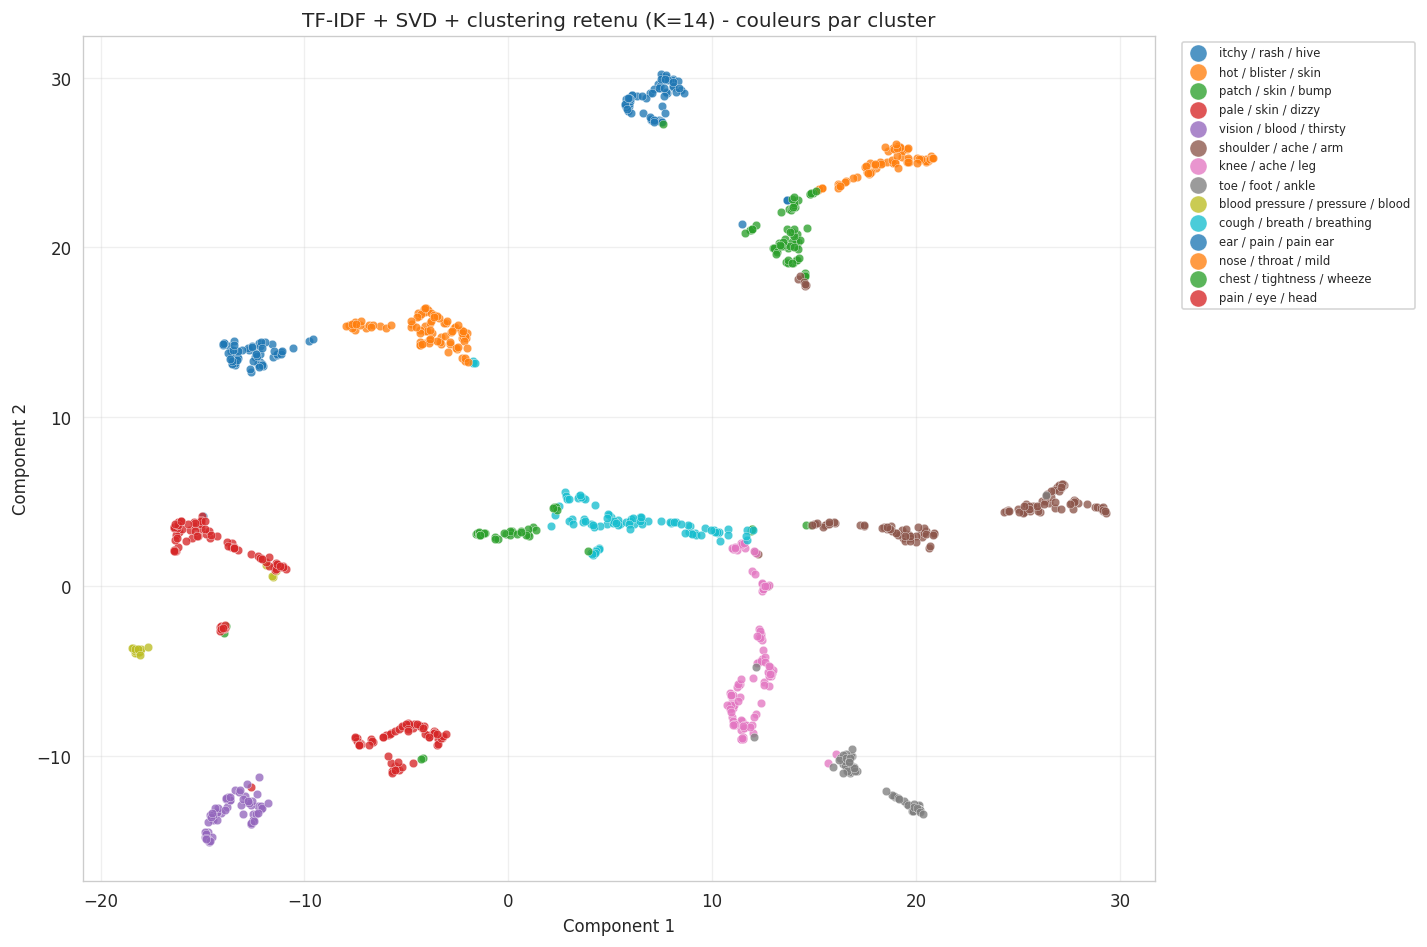

In [18]:
# Scatter 2D des clusters (rendu principal)
fig, ax = plt.subplots(figsize=(12, 8))

unique_labels = sorted(set(best_labels))
valid_labels = [c for c in unique_labels if c != -1]
k_display = len(valid_labels)

# Palette: tab10 pour les clusters, gris pour le bruit.
palette = sns.color_palette('tab10', max(k_display, 1))
cluster_color = {cid: palette[i % len(palette)] for i, cid in enumerate(valid_labels)}
cluster_color[-1] = (0.72, 0.72, 0.72)

for cid in unique_labels:
    mask = best_labels == cid
    label_str = cluster_names.get(cid, f'Cluster {cid}')
    ax.scatter(
        best_X_2d[mask, 0],
        best_X_2d[mask, 1],
        c=[cluster_color.get(cid, (0.5, 0.5, 0.5))],
        s=26,
        alpha=0.78,
        label=label_str,
        edgecolors='white',
        linewidths=0.25,
    )

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_title(f'TF-IDF + SVD + clustering retenu (K={k_display}) - couleurs par cluster')
ax.legend(fontsize=7, markerscale=2, loc='upper left', bbox_to_anchor=(1.02, 1.0))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

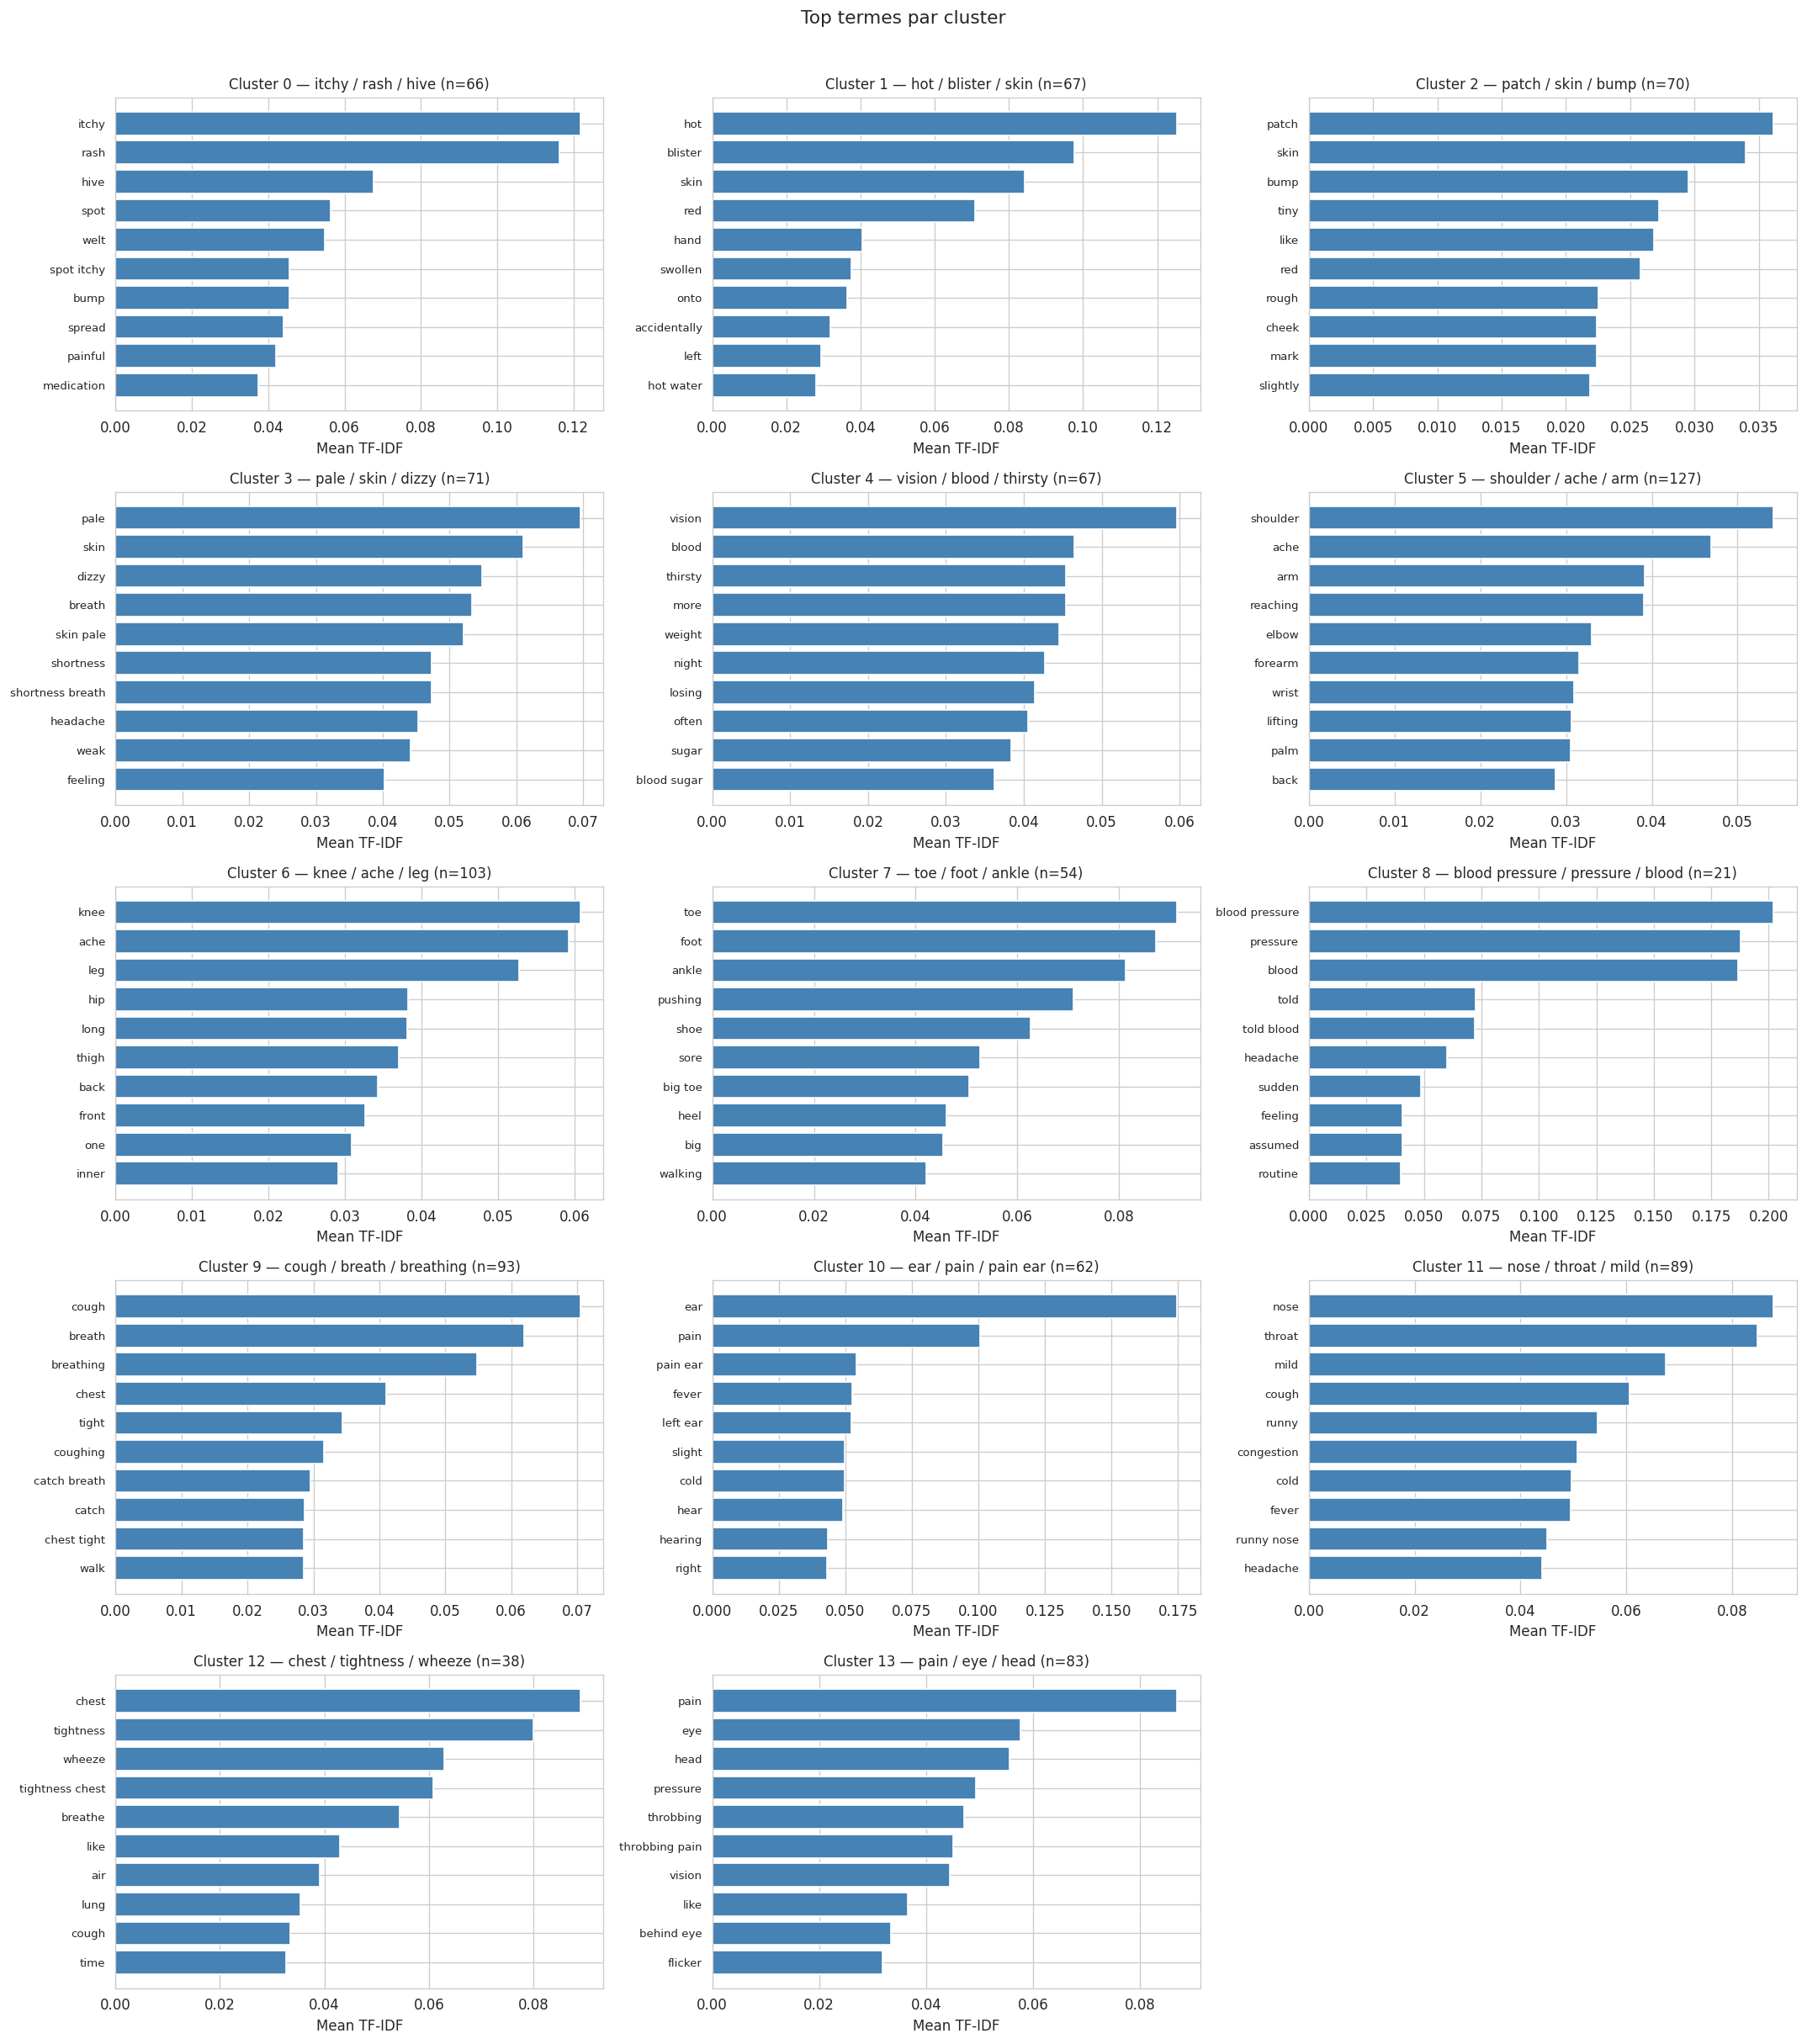

In [19]:
# Top termes TF-IDF par cluster
valid_labels = sorted(set(best_labels) - {-1})
n_plots = len(valid_labels)
n_cols = min(n_plots, 3)
n_rows = (n_plots + n_cols - 1) // n_cols
n_terms = 10

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten() if n_plots > 1 else np.array([axes])

for i, cid in enumerate(valid_labels):
    mask = best_labels == cid
    cluster_tfidf = np.asarray(X_tfidf[mask].mean(axis=0)).flatten()
    top_idx = cluster_tfidf.argsort()[::-1][:n_terms]

    ax = axes[i]
    ax.barh(range(n_terms), cluster_tfidf[top_idx][::-1], color='steelblue')
    ax.set_yticks(range(n_terms))
    ax.set_yticklabels(vocab[top_idx][::-1], fontsize=8)
    ax.set_title(f'Cluster {cid} — {cluster_names.get(cid, "")} (n={mask.sum()})', fontsize=10)
    ax.set_xlabel('Mean TF-IDF')

for j in range(n_plots, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Top termes par cluster', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

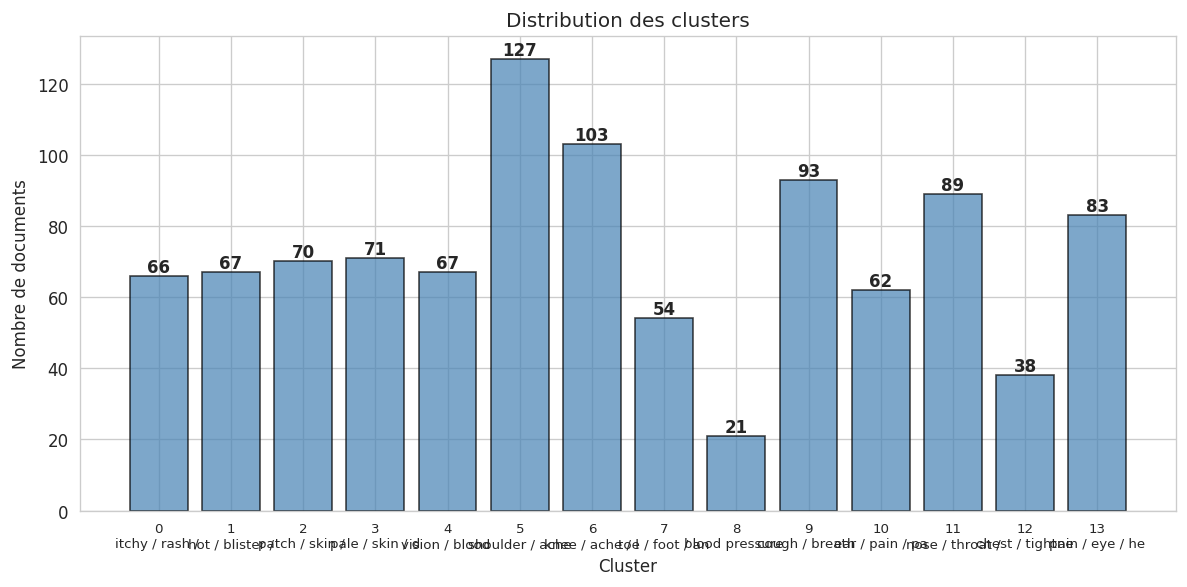

In [20]:
# Distribution des clusters
fig, ax = plt.subplots(figsize=(10, 5))
unique, counts = np.unique(best_labels, return_counts=True)
bars = ax.bar(unique, counts, color='steelblue', edgecolor='black', alpha=0.7)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height(),
            str(int(count)), ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xlabel('Cluster')
ax.set_ylabel('Nombre de documents')
ax.set_title('Distribution des clusters')
ax.set_xticks(unique)
ax.set_xticklabels([f'{c}\n{cluster_names.get(c, "")[:15]}' for c in unique], fontsize=8)
plt.tight_layout()
plt.show()

## 8. Métriques finales et export

Métriques : Silhouette, Calinski-Harabasz, Davies-Bouldin. Export vers `results/cluster_labels.csv`.

In [21]:
# Metriques finales (sur l'espace complet de la strategie retenue)
valid = best_labels >= 0
print(f'Strategie retenue : {best_name}')
print(f'Nombre de clusters : {n_clusters_final}')
print(f'Documents classes  : {valid.sum()} / {len(best_labels)}')

if len(set(best_labels[valid])) >= 2:
    sil_final = silhouette_score(best_eval_X[valid], best_labels[valid])
    ch_final = calinski_harabasz_score(best_eval_X[valid], best_labels[valid])
    db_final = davies_bouldin_score(best_eval_X[valid], best_labels[valid])
    print(f'Silhouette         : {sil_final:.3f}')
    print(f'Calinski-Harabasz  : {ch_final:.1f}')
    print(f'Davies-Bouldin     : {db_final:.3f}')
else:
    print('Metriques indisponibles: moins de 2 clusters valides.')

Strategie retenue : TF-IDF + SVD + HDBSCAN
Nombre de clusters : 14
Documents classes  : 1011 / 1011
Silhouette         : 0.400
Calinski-Harabasz  : 922.4
Davies-Bouldin     : 0.901


In [22]:
# Export des resultats
results_dir = os.path.join(PROJECT_ROOT, 'results')
os.makedirs(results_dir, exist_ok=True)

out_path = os.path.join(results_dir, 'cluster_labels.csv')

if len(doc_ids) != len(best_labels):
    raise ValueError(
        f'Incoherence export: {len(doc_ids)} ids pour {len(best_labels)} labels.'
    )

with open(out_path, 'w', encoding='utf-8', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['doc_id', 'cluster', 'cluster_name'])
    for doc_id, cl in zip(doc_ids, best_labels):
        writer.writerow([doc_id, cl, cluster_names.get(cl, '')])

print(f'Resultats exportes : {out_path}')

Resultats exportes : /home/nathan-muzay/A_tek/S3/AIA/CVRIE/results/cluster_labels.csv


## 9. Nouvelle strategie C — Agglomerative Clustering (version amelioree)

On renforce la methode **hierarchique agglomerative** pour mieux rivaliser avec HDBSCAN.

### Ce qui change
- Recherche sur **plusieurs espaces**: `SVD` et `UMAP` (si disponible).
- Recherche sur **plusieurs liaisons/mesures**: `ward/euclidean`, `average/cosine`, `average/euclidean`.
- Recherche de `K` orientee vers des partitions plus fines et mieux separees.

Cette version cherche des clusters plus distincts, avec un compromis compacite/separation mieux adapte au corpus.

In [23]:
from sklearn.cluster import AgglomerativeClustering

# Strategie C amelioree: recherche multi-espace, multi-liaison, multi-metric.
k_min_c = 6
k_max_c = min(20, max(k_min_c + 2, int(np.sqrt(len(cleaned)) * 2.1)))
K_search_c = range(k_min_c, k_max_c + 1)

TARGET_C_MIN = 10
TARGET_C_MAX = 14
min_cluster_size_target = max(8, int(0.01 * len(cleaned)))

candidate_spaces = [('SVD', X_svd)]
if 'features_b' in globals() and features_b is not None:
    candidate_spaces.append(('UMAP', features_b))

candidate_specs = []
for space_name, X_space in candidate_spaces:
    candidate_specs.extend([
        (space_name, X_space, 'ward', 'euclidean'),
        (space_name, X_space, 'average', 'cosine'),
        (space_name, X_space, 'average', 'euclidean'),
    ])

search_rows_c = []
best_cfg_c = None
best_score_c = -1e9
best_target_cfg_c = None
best_target_score_c = -1e9

for space_name, X_space, linkage, metric in candidate_specs:
    for k in K_search_c:
        if linkage == 'ward' and metric != 'euclidean':
            continue

        agg = AgglomerativeClustering(
            n_clusters=k,
            linkage=linkage,
            metric=metric,
        )
        labels_tmp = agg.fit_predict(X_space)

        # Pour la silhouette, cosine est pertinent avec average/cosine, sinon euclidean.
        sil_metric = 'cosine' if metric == 'cosine' else 'euclidean'
        sil = silhouette_score(X_space, labels_tmp, metric=sil_metric)
        ch = calinski_harabasz_score(X_space, labels_tmp)
        db = davies_bouldin_score(X_space, labels_tmp)

        sizes = np.array([(labels_tmp == c).sum() for c in sorted(set(labels_tmp))], dtype=float)
        min_size = int(sizes.min())
        tiny_ratio = float((sizes < min_cluster_size_target).mean())
        imbalance = float(sizes.std() / max(sizes.mean(), 1.0))
        undersize_penalty = max(0.0, (min_cluster_size_target - min_size) / min_cluster_size_target)

        if k < TARGET_C_MIN:
            cluster_target_penalty = 0.05 * (TARGET_C_MIN - k)
        elif k > TARGET_C_MAX:
            cluster_target_penalty = 0.04 * (k - TARGET_C_MAX)
        else:
            cluster_target_penalty = -0.02

        rank = (
            1.25 * sil
            - 0.040 * db
            + 0.00002 * ch
            - 0.07 * tiny_ratio
            - 0.05 * imbalance
            - 0.20 * undersize_penalty
            - cluster_target_penalty
        )

        row = {
            'space': space_name,
            'metric': metric,
            'linkage': linkage,
            'k': int(k),
            'sil': float(sil),
            'ch': float(ch),
            'db': float(db),
            'min_size': int(min_size),
            'tiny_ratio': float(tiny_ratio),
            'imbalance': float(imbalance),
            'undersize_penalty': float(undersize_penalty),
            'target_penalty': float(cluster_target_penalty),
            'rank': float(rank),
        }
        search_rows_c.append(row)

        if TARGET_C_MIN <= k <= TARGET_C_MAX and rank > best_target_score_c:
            best_target_score_c = rank
            best_target_cfg_c = row
        if rank > best_score_c:
            best_score_c = rank
            best_cfg_c = row

if best_target_cfg_c is not None:
    best_cfg_c = best_target_cfg_c
    print(f'Selection ciblee Agglomerative activee: K dans [{TARGET_C_MIN}, {TARGET_C_MAX}]')
else:
    print('Aucune config Agglomerative dans la cible, fallback sur le meilleur score global.')

# Modele final strategie C
best_k_c = int(best_cfg_c['k'])
aggl_metric = best_cfg_c['metric']
aggl_linkage = best_cfg_c['linkage']
aggl_space_name = best_cfg_c['space']

if aggl_space_name == 'UMAP' and 'features_b' in globals() and features_b is not None:
    X_aggl = features_b
    X_2d_c = features_b_vis if 'features_b_vis' in globals() and features_b_vis is not None else features_b[:, :2]
else:
    X_aggl = X_svd
    X_2d_c = X_svd[:, :2]

agg_final = AgglomerativeClustering(
    n_clusters=best_k_c,
    linkage=aggl_linkage,
    metric=aggl_metric,
 )
labels_c = agg_final.fit_predict(X_aggl)

# Metriques de reference pour la strategie C
sil_metric_final = 'cosine' if aggl_metric == 'cosine' else 'euclidean'
sil_c = silhouette_score(X_aggl, labels_c, metric=sil_metric_final)
db_c = davies_bouldin_score(X_aggl, labels_c)
ch_c = calinski_harabasz_score(X_aggl, labels_c)

df_c_search = pd.DataFrame(search_rows_c).sort_values('rank', ascending=False).reset_index(drop=True)
print(f'Strategie C — Agglomerative ({aggl_space_name}, {aggl_linkage}/{aggl_metric}), K={best_k_c}')
print(f'  Silhouette         : {sil_c:.3f}')
print(f'  Calinski-Harabasz  : {ch_c:.1f}')
print(f'  Davies-Bouldin     : {db_c:.3f}')
print(f'  Taille min cluster : {int((np.bincount(labels_c)).min())} docs')
print('\nTop configurations testees (C):')
display(df_c_search.head(14))

print('\nTaille des clusters (C):')
for cid in sorted(set(labels_c)):
    print(f'  Cluster {cid}: {(labels_c == cid).sum()} docs')

Selection ciblee Agglomerative activee: K dans [10, 14]
Strategie C — Agglomerative (UMAP, ward/euclidean), K=14
  Silhouette         : 0.407
  Calinski-Harabasz  : 929.0
  Davies-Bouldin     : 0.868
  Taille min cluster : 45 docs

Top configurations testees (C):


,space,metric,linkage,k,sil,ch,db,min_size,tiny_ratio,imbalance,undersize_penalty,target_penalty,rank
0,UMAP,cosine,average,6,0.650170,983.711849,0.809772,89,0.000000,0.391688,0.0,0.20,0.580411
1,UMAP,euclidean,ward,14,0.407337,929.001922,0.867991,45,0.000000,0.320434,0.0,-0.02,0.497010
2,UMAP,euclidean,ward,13,0.405624,927.641402,0.898375,52,0.000000,0.286869,0.0,-0.02,0.495305
3,UMAP,cosine,average,14,0.544831,774.326525,0.944999,2,0.071429,0.570647,0.8,-0.02,0.485193
4,UMAP,euclidean,ward,12,0.396664,901.723431,0.898084,52,0.000000,0.318753,0.0,-0.02,0.482003
5,UMAP,euclidean,ward,11,0.378680,875.053423,0.957535,52,0.000000,0.334951,0.0,-0.02,0.455802
6,UMAP,cosine,average,13,0.516581,738.939450,0.986239,2,0.076923,0.594692,0.8,-0.02,0.445936
7,UMAP,euclidean,ward,10,0.369594,862.121847,0.984720,52,0.000000,0.311987,0.0,-0.02,0.444247
8,UMAP,euclidean,ward,15,0.409833,933.430986,0.875828,45,0.000000,0.255365,0.0,0.04,0.443158
9,UMAP,cosine,average,7,0.503128,861.894573,0.953224,19,0.000000,0.545207,0.0,0.15,0.430758



Taille des clusters (C):
  Cluster 0: 126 docs
  Cluster 1: 78 docs
  Cluster 2: 114 docs
  Cluster 3: 76 docs
  Cluster 4: 94 docs
  Cluster 5: 51 docs
  Cluster 6: 71 docs
  Cluster 7: 64 docs
  Cluster 8: 59 docs
  Cluster 9: 52 docs
  Cluster 10: 58 docs
  Cluster 11: 67 docs
  Cluster 12: 56 docs
  Cluster 13: 45 docs


## 10. Comparatif complet — HDBSCAN vs Agglomerative

Objectif: comparer les deux approches avec les **memes familles de visuels** que dans le notebook:
- **Scatter 2D**
- **Top termes TF-IDF par cluster**
- **Distribution des clusters**

Lecture du comparatif:
- **Silhouette**: plus proche de `1` = clusters mieux separes.
- **Calinski-Harabasz**: plus eleve = meilleure compacite/separation globale.
- **Davies-Bouldin**: plus faible = clusters plus denses et mieux distincts.
- **Bruit (`-1`)**: uniquement pour HDBSCAN, represente des points non assignes a un cluster dense.

Comparaison finale des performances:


,Methode,Clusters (hors bruit),Docs assignes,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,HDBSCAN (espace B),14,1011,0.400,922.4,0.901
1,"Agglomerative (UMAP, ward/euclidean)",14,1011,0.407,929.0,0.868



Optimisation HDBSCAN (Top 10):


,min_cluster,min_samp,eps,n_clusters,noise,sil,db,rank
0,14,5.0,0.00,14,295,0.505943,0.693375,0.779829
1,14,5.0,0.01,14,295,0.505943,0.693375,0.779829
2,14,5.0,0.02,14,295,0.505943,0.693375,0.779829
3,14,5.0,0.04,14,295,0.505943,0.693375,0.779829
4,14,5.0,0.06,14,295,0.505943,0.693375,0.779829
5,14,5.0,0.10,14,295,0.505943,0.693375,0.779829
6,16,5.0,0.00,14,295,0.505943,0.693375,0.779829
7,16,5.0,0.01,14,295,0.505943,0.693375,0.779829
8,16,5.0,0.02,14,295,0.505943,0.693375,0.779829
9,16,5.0,0.04,14,295,0.505943,0.693375,0.779829


Optimisation Agglomerative (Top 10):


,space,linkage,metric,k,min_size,sil,db,rank
0,UMAP,average,cosine,6,89,0.650170,0.809772,0.580411
1,UMAP,ward,euclidean,14,45,0.407337,0.867991,0.497010
2,UMAP,ward,euclidean,13,52,0.405624,0.898375,0.495305
3,UMAP,average,cosine,14,2,0.544831,0.944999,0.485193
4,UMAP,ward,euclidean,12,52,0.396664,0.898084,0.482003
5,UMAP,ward,euclidean,11,52,0.378680,0.957535,0.455802
6,UMAP,average,cosine,13,2,0.516581,0.986239,0.445936
7,UMAP,ward,euclidean,10,52,0.369594,0.984720,0.444247
8,UMAP,ward,euclidean,15,45,0.409833,0.875828,0.443158
9,UMAP,average,cosine,7,19,0.503128,0.953224,0.430758


Meilleures configurations retenues:


,Methode,Parametres,n_clusters,sil,rank
0,HDBSCAN,"min_cluster=14, min_samp=5, eps=0.0",14,0.505943,0.779829
1,Agglomerative,"space=UMAP, linkage=ward, metric=euclidean, k=14",14,0.407337,0.497010


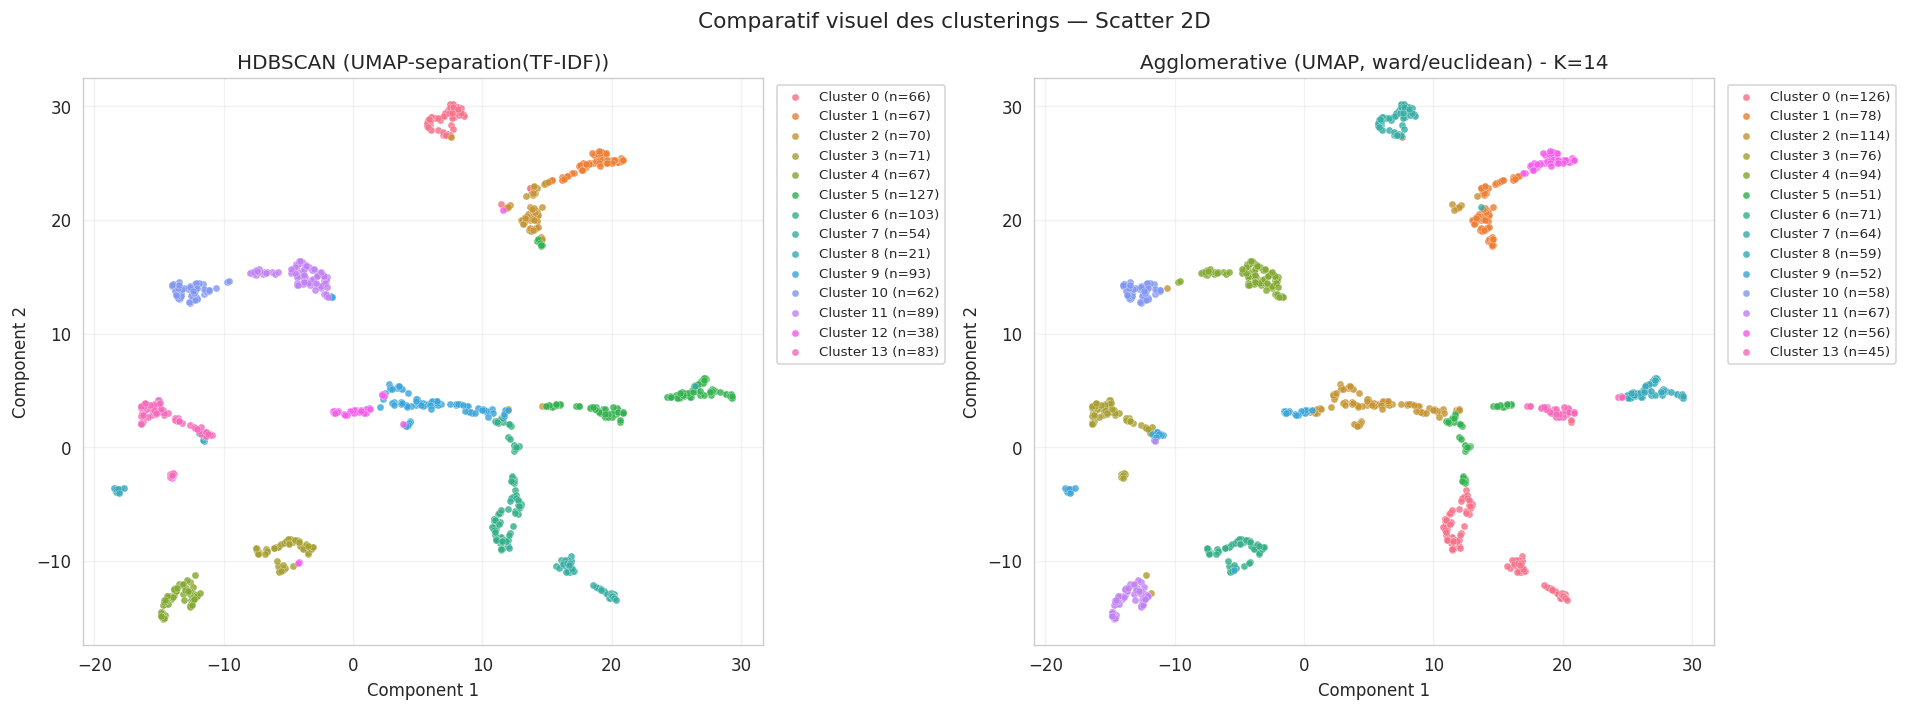

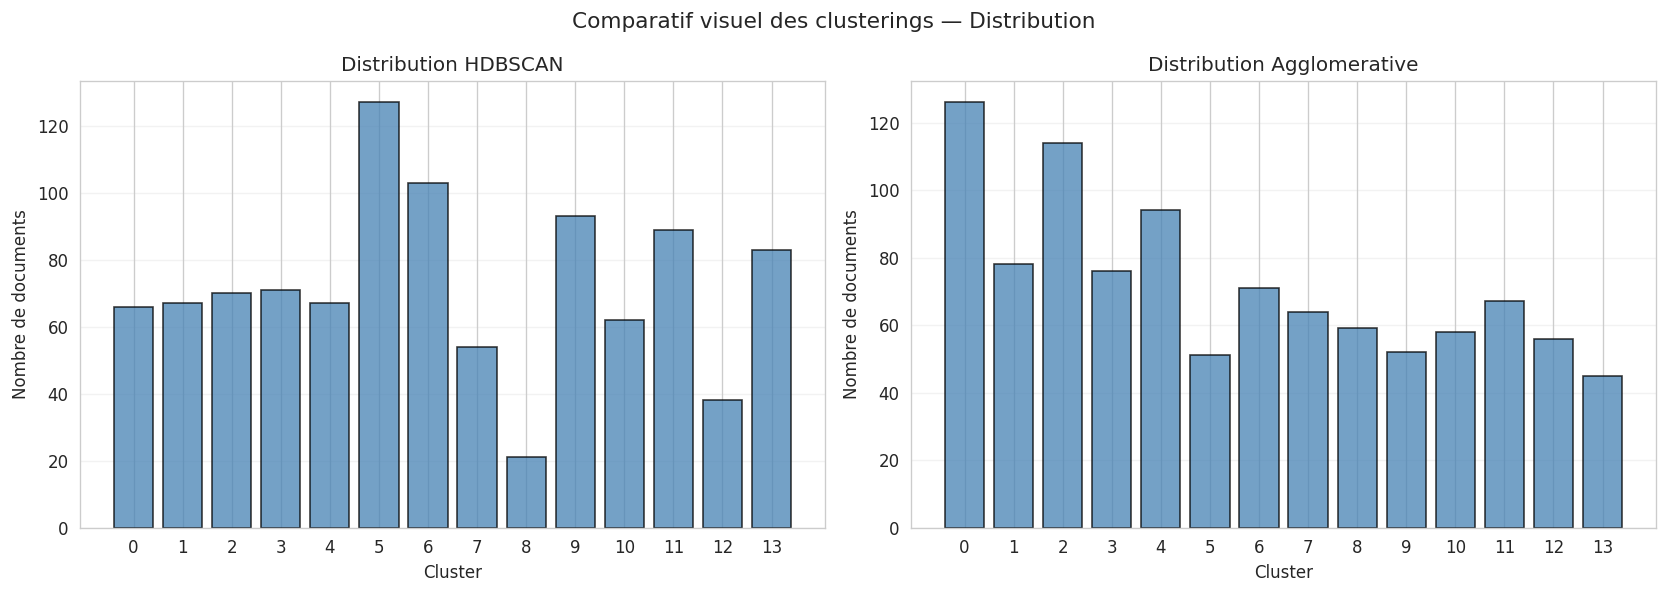

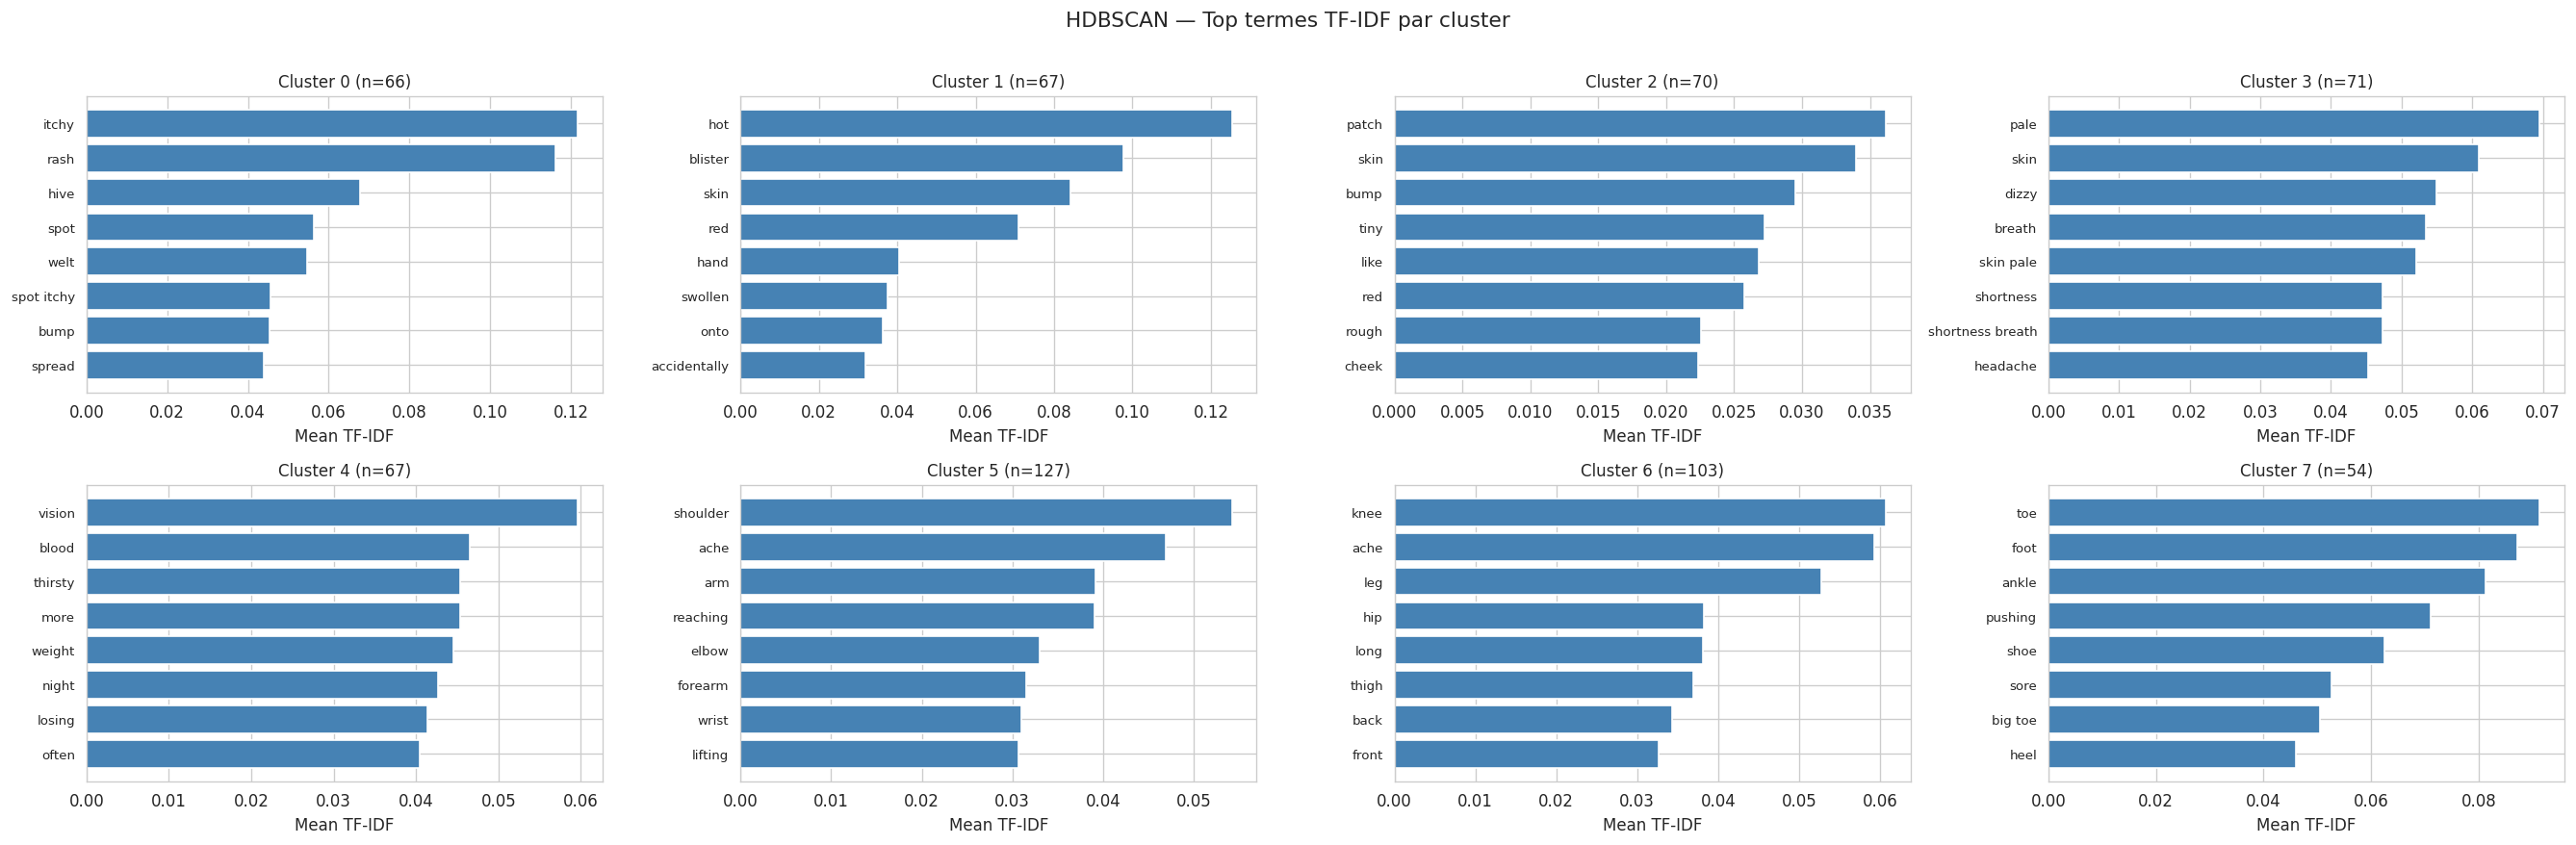

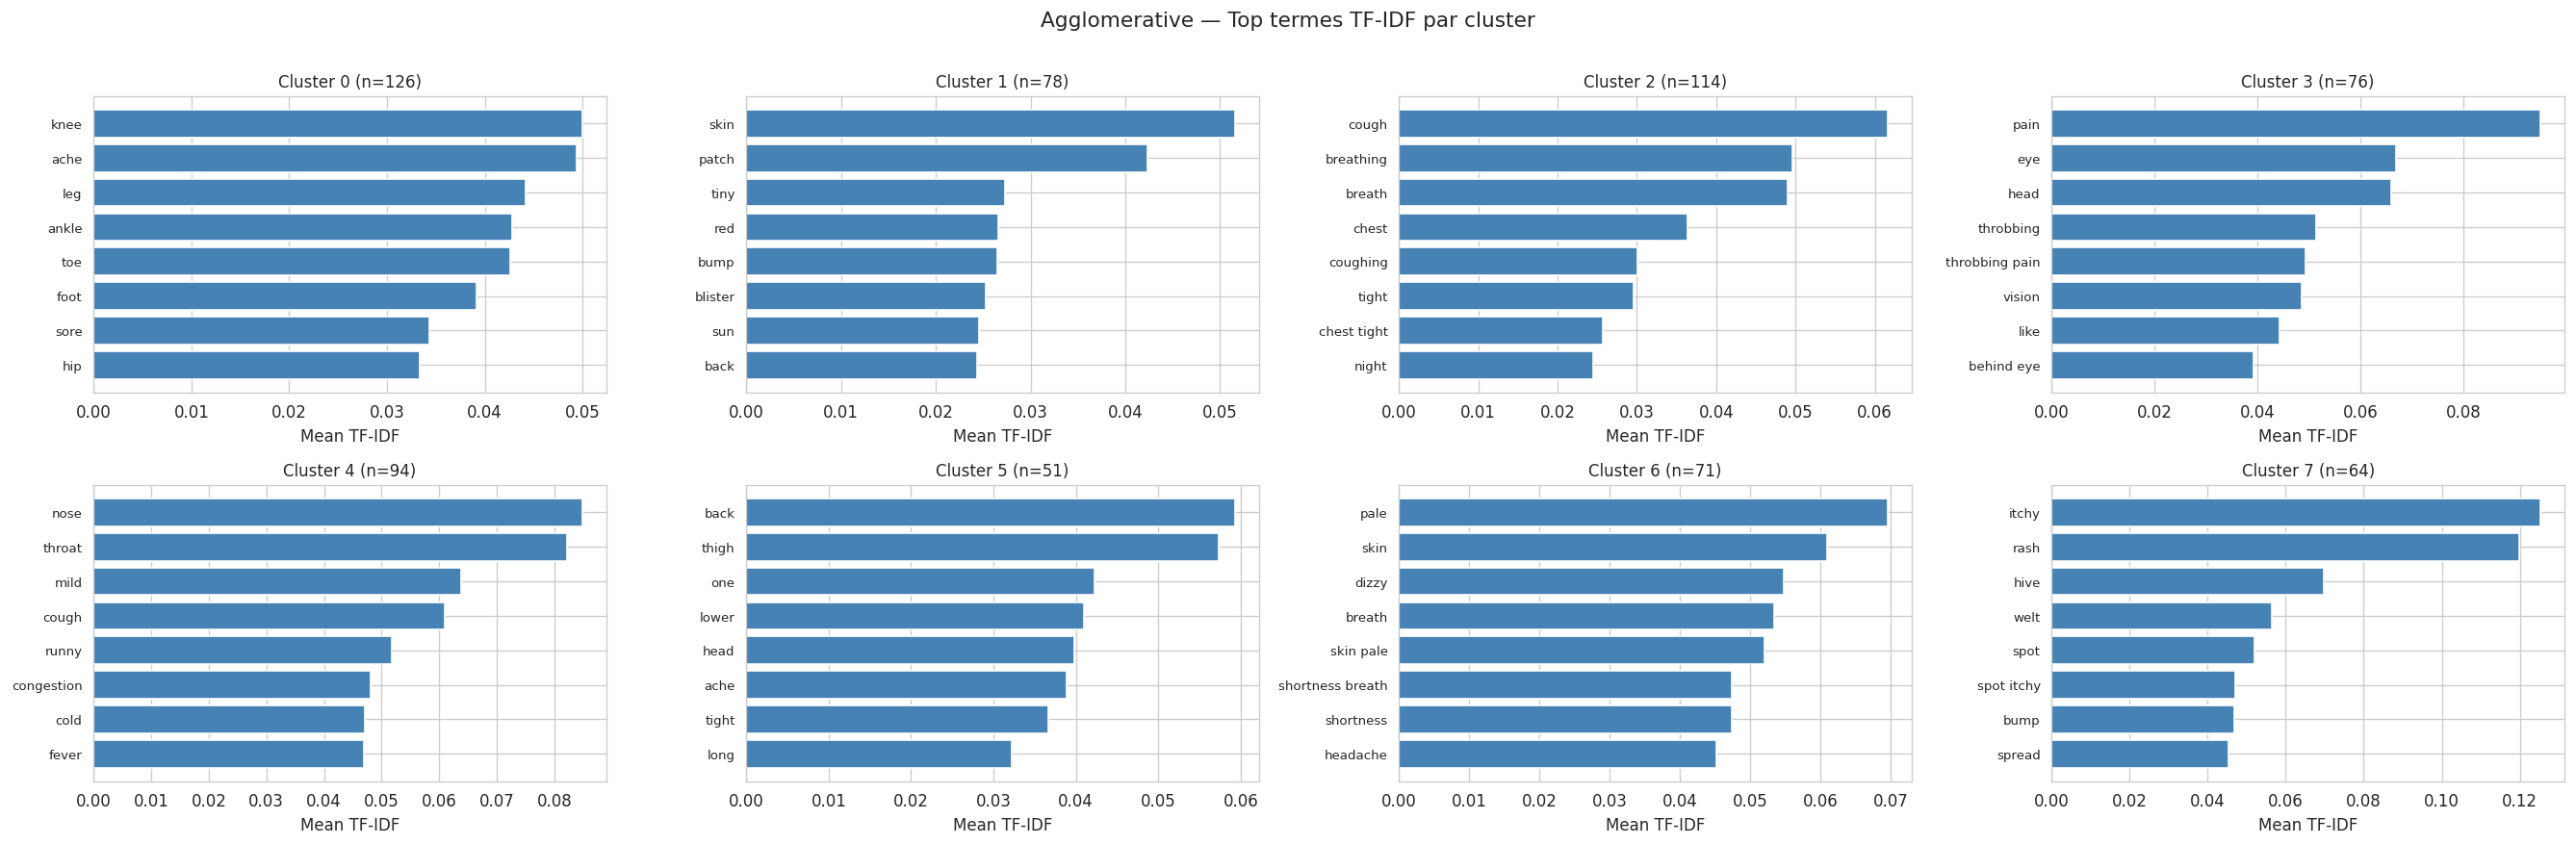

In [24]:
def _safe_cluster_metrics(X, labels, sil_metric='euclidean'):
    """Calcule les metriques en ignorant le bruit (-1) si present."""
    labels = np.asarray(labels)
    valid = labels >= 0
    uniq = set(labels[valid])
    if valid.sum() <= 2 or len(uniq) < 2:
        return np.nan, np.nan, np.nan, int(valid.sum()), int(len(uniq))

    sil = silhouette_score(X[valid], labels[valid], metric=sil_metric)
    ch = calinski_harabasz_score(X[valid], labels[valid])
    db = davies_bouldin_score(X[valid], labels[valid])
    return float(sil), float(ch), float(db), int(valid.sum()), int(len(uniq))

def _plot_cluster_distribution(ax, labels, title):
    labels_arr = np.asarray(labels)
    uniq, counts = np.unique(labels_arr, return_counts=True)
    ax.bar(uniq, counts, color='steelblue', edgecolor='black', alpha=0.75)
    ax.set_title(title)
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Nombre de documents')
    ax.set_xticks(uniq)
    ax.grid(True, axis='y', alpha=0.25)

def _plot_top_terms_grid(labels, X_tfidf, vocab, title, n_terms=8, max_clusters=8):
    valid_labels = sorted(set(labels) - {-1})[:max_clusters]
    if len(valid_labels) == 0:
        print(f'{title}: aucun cluster valide pour afficher les top termes.')
        return

    n_plots = len(valid_labels)
    n_cols = min(4, n_plots)
    n_rows = (n_plots + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.6 * n_cols, 3.6 * n_rows))
    axes = np.array(axes).flatten() if n_plots > 1 else np.array([axes])

    for i, cid in enumerate(valid_labels):
        mask = np.asarray(labels) == cid
        cluster_tfidf = np.asarray(X_tfidf[mask].mean(axis=0)).flatten()
        top_idx = cluster_tfidf.argsort()[::-1][:n_terms]

        ax = axes[i]
        ax.barh(range(n_terms), cluster_tfidf[top_idx][::-1], color='steelblue')
        ax.set_yticks(range(n_terms))
        ax.set_yticklabels(vocab[top_idx][::-1], fontsize=8)
        ax.set_title(f'Cluster {cid} (n={int(mask.sum())})', fontsize=10)
        ax.set_xlabel('Mean TF-IDF')

    for j in range(n_plots, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

# Donnees HDBSCAN (Strategie B)
has_hdbscan_result = results_b is not None and 'labels' in results_b and 'X_2d' in results_b

if has_hdbscan_result:
    labels_h = results_b['labels']
    X_2d_h = results_b['X_2d']
    X_eval_h = results_b.get('X_eval', X_svd)
    sil_h, ch_h, db_h, n_valid_h, n_cl_h = _safe_cluster_metrics(X_eval_h, labels_h, sil_metric='euclidean')
else:
    labels_h = None
    X_2d_h = None
    sil_h, ch_h, db_h, n_valid_h, n_cl_h = (np.nan, np.nan, np.nan, 0, 0)

# Metriques de la strategie C
sil_metric_c = 'cosine' if aggl_metric == 'cosine' else 'euclidean'
sil_new, ch_new, db_new, n_valid_new, n_cl_new = _safe_cluster_metrics(X_aggl, labels_c, sil_metric=sil_metric_c)

comparison_rows = [
    {
        'Methode': 'HDBSCAN (espace B)',
        'Clusters (hors bruit)': n_cl_h,
        'Docs assignes': n_valid_h,
        'Silhouette': round(float(sil_h), 3) if pd.notna(sil_h) else np.nan,
        'Calinski-Harabasz': round(float(ch_h), 1) if pd.notna(ch_h) else np.nan,
        'Davies-Bouldin': round(float(db_h), 3) if pd.notna(db_h) else np.nan,
    },
    {
        'Methode': f'Agglomerative ({aggl_space_name}, {aggl_linkage}/{aggl_metric})',
        'Clusters (hors bruit)': n_cl_new,
        'Docs assignes': n_valid_new,
        'Silhouette': round(float(sil_new), 3) if pd.notna(sil_new) else np.nan,
        'Calinski-Harabasz': round(float(ch_new), 1) if pd.notna(ch_new) else np.nan,
        'Davies-Bouldin': round(float(db_new), 3) if pd.notna(db_new) else np.nan,
    },
]

df_compare = pd.DataFrame(comparison_rows)
print('Comparaison finale des performances:')
display(df_compare)

if 'df_bench' in globals() and isinstance(df_bench, pd.DataFrame) and len(df_bench) > 0:
    hdb_cols = ['min_cluster', 'min_samp', 'eps', 'n_clusters', 'noise', 'sil', 'db', 'rank']
    df_hdb_opt = df_bench[hdb_cols].copy().head(10)
else:
    df_hdb_opt = pd.DataFrame()

if 'df_c_search' in globals() and isinstance(df_c_search, pd.DataFrame) and len(df_c_search) > 0:
    aggl_cols = ['space', 'linkage', 'metric', 'k', 'min_size', 'sil', 'db', 'rank']
    df_aggl_opt = df_c_search[aggl_cols].copy().head(10)
else:
    df_aggl_opt = pd.DataFrame()

print('\nOptimisation HDBSCAN (Top 10):')
display(df_hdb_opt if len(df_hdb_opt) else pd.DataFrame([{'info': 'Aucune grille HDBSCAN disponible'}]))

print('Optimisation Agglomerative (Top 10):')
display(df_aggl_opt if len(df_aggl_opt) else pd.DataFrame([{'info': 'Aucune grille Agglomerative disponible'}]))

best_hdb_row = None
if 'best_config' in globals() and isinstance(best_config, dict):
    best_hdb_row = {
        'Methode': 'HDBSCAN',
        'Parametres': f"min_cluster={best_config.get('min_cluster')}, min_samp={best_config.get('min_samp')}, eps={best_config.get('eps')}",
        'n_clusters': int(best_config.get('n_clusters', -1)),
        'sil': float(best_config.get('sil', np.nan)),
        'rank': float(best_config.get('rank', np.nan)),
    }

best_aggl_row = None
if 'best_cfg_c' in globals() and isinstance(best_cfg_c, dict):
    best_aggl_row = {
        'Methode': 'Agglomerative',
        'Parametres': f"space={best_cfg_c.get('space')}, linkage={best_cfg_c.get('linkage')}, metric={best_cfg_c.get('metric')}, k={best_cfg_c.get('k')}",
        'n_clusters': int(best_cfg_c.get('k', -1)),
        'sil': float(best_cfg_c.get('sil', np.nan)),
        'rank': float(best_cfg_c.get('rank', np.nan)),
    }

rows_best = [r for r in [best_hdb_row, best_aggl_row] if r is not None]
print('Meilleures configurations retenues:')
display(pd.DataFrame(rows_best))

def _palette_for(n):
    if n <= 10:
        return sns.color_palette('tab10', n)
    return sns.color_palette('husl', n)

# 1) Scatter compare
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax0 = axes[0]
if has_hdbscan_result:
    unique_h = sorted(set(labels_h))
    colors_h = _palette_for(max(len(unique_h) - (1 if -1 in unique_h else 0), 1))
    color_idx = 0
    for cid in unique_h:
        m = labels_h == cid
        if cid == -1:
            color = (0.72, 0.72, 0.72)
            label = f'Bruit (-1) (n={m.sum()})'
        else:
            color = colors_h[color_idx]
            color_idx += 1
            label = f'Cluster {cid} (n={m.sum()})'
        ax0.scatter(
            X_2d_h[m, 0], X_2d_h[m, 1],
            s=18, alpha=0.82, c=[color], label=label,
            edgecolors='white', linewidths=0.2,
        )
    space_name = results_b.get('feature_space', 'espace B')
    ax0.set_title(f'HDBSCAN ({space_name})')
    ax0.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1.0))
else:
    ax0.text(0.5, 0.5, 'HDBSCAN non disponible', ha='center', va='center', fontsize=11)
    ax0.set_title('HDBSCAN (espace B)')

ax0.set_xlabel('Component 1')
ax0.set_ylabel('Component 2')
ax0.grid(True, alpha=0.25)

ax1 = axes[1]
unique_c = sorted(set(labels_c))
colors_c = _palette_for(len(unique_c))
for i, cid in enumerate(unique_c):
    m = labels_c == cid
    ax1.scatter(
        X_2d_c[m, 0], X_2d_c[m, 1],
        s=18, alpha=0.82, c=[colors_c[i]], label=f'Cluster {cid} (n={m.sum()})',
        edgecolors='white', linewidths=0.2,
    )

ax1.set_title(f'Agglomerative ({aggl_space_name}, {aggl_linkage}/{aggl_metric}) - K={best_k_c}')
ax1.set_xlabel('Component 1')
ax1.set_ylabel('Component 2')
ax1.grid(True, alpha=0.25)
ax1.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1.0), ncol=1)

plt.suptitle('Comparatif visuel des clusterings — Scatter 2D', fontsize=13)
plt.tight_layout()
plt.show()

# 2) Distribution comparee
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if has_hdbscan_result:
    _plot_cluster_distribution(axes[0], labels_h, 'Distribution HDBSCAN')
else:
    axes[0].text(0.5, 0.5, 'HDBSCAN non disponible', ha='center', va='center', fontsize=11)
    axes[0].set_title('Distribution HDBSCAN')
_plot_cluster_distribution(axes[1], labels_c, 'Distribution Agglomerative')
plt.suptitle('Comparatif visuel des clusterings — Distribution', fontsize=13)
plt.tight_layout()
plt.show()

# 3) Top termes par cluster (meme style que section 7)
if has_hdbscan_result:
    _plot_top_terms_grid(labels_h, X_tfidf, vocab, 'HDBSCAN — Top termes TF-IDF par cluster', n_terms=8, max_clusters=8)
_plot_top_terms_grid(labels_c, X_tfidf, vocab, 'Agglomerative — Top termes TF-IDF par cluster', n_terms=8, max_clusters=8)

## 11. Prediction d'une nouvelle ligne avec HDBSCAN

Cette section permet d'ecrire un nouveau texte, de le projeter dans le meme espace que la Strategie B (HDBSCAN), de predire son cluster, puis de l'afficher sur un scatter 2D.

Remarque: HDBSCAN assigne le point a un cluster existant (ou `-1` pour bruit). Le point est affiche avec un style visuel distinct (`Nouveau point`) pour le reperer immediatement.

Texte original : I broke my leg.
Texte nettoye  : broke leg
Cluster predit : -1
Confiance      : 0.000
Interpretation : HDBSCAN considere ce point comme bruit.


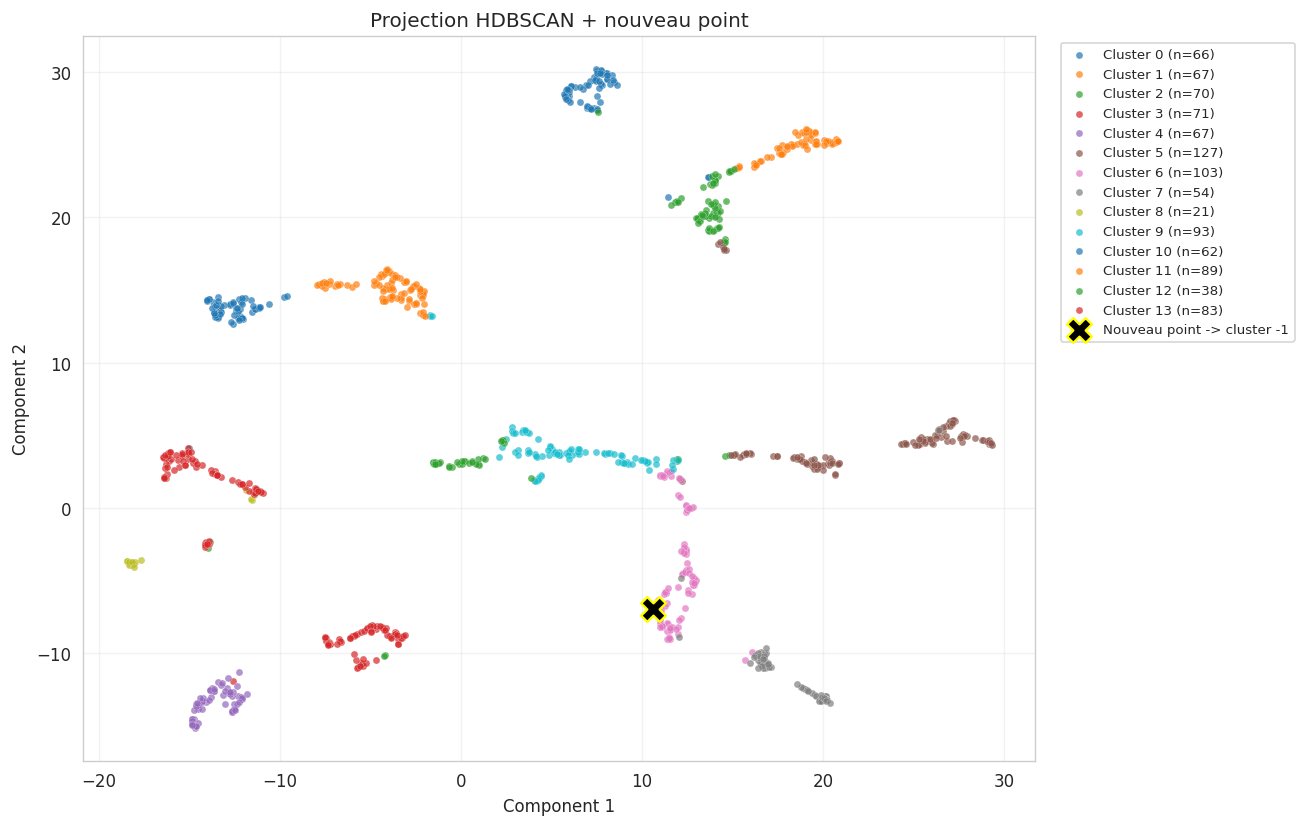

In [ ]:
# Entrez ici le nouveau texte a tester ########################################################################""
new_text = "I broke my leg."

required_objects = ['vectorizer', 'simple_clean_text', 'features_b', 'clusterer_best', 'results_b']
missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(
        "Objets manquants pour la prediction: "
        + ", ".join(missing)
        + ". Execute d'abord les cellules jusqu'a la Strategie B (HDBSCAN)."
    )

if not HAS_HDBSCAN:
    raise RuntimeError("Le package hdbscan n'est pas disponible dans cet environnement.")

if not hasattr(_hdbscan, 'approximate_predict'):
    raise RuntimeError("approximate_predict est indisponible dans votre version de hdbscan.")

# 1) Meme pipeline de pre-processing + vectorisation
new_text_clean = simple_clean_text(new_text)
X_new_tfidf = vectorizer.transform([new_text_clean])

# 2) Projection dans le meme espace que le fit HDBSCAN
if 'umap_clust' in globals() and umap_clust is not None and features_b_name.startswith('UMAP'):
    X_new_feat = umap_clust.transform(X_new_tfidf)
else:
    if 'svd' not in globals() or svd is None:
        raise RuntimeError("SVD introuvable pour la projection de la nouvelle ligne.")
    X_new_feat = svd.transform(X_new_tfidf)

# 3) Prediction HDBSCAN (cluster existant ou bruit)
pred_label, pred_strength = _hdbscan.approximate_predict(clusterer_best, X_new_feat)
pred_label = int(pred_label[0])
pred_strength = float(pred_strength[0])

# Projection 2D du nouveau point pour affichage
if 'umap_vis' in globals() and umap_vis is not None and features_b_vis is not None and features_b_name.startswith('UMAP'):
    X_new_2d = umap_vis.transform(X_new_feat)
else:
    X_new_2d = X_new_feat[:, :2]

print('Texte original :', new_text)
print('Texte nettoye  :', new_text_clean)
print('Cluster predit :', pred_label)
print(f'Confiance      : {pred_strength:.3f}')
if pred_label == -1:
    print('Interpretation : HDBSCAN considere ce point comme bruit.')

# 4) Affichage: clusters existants + nouveau point distinct
labels_plot = np.asarray(results_b['labels'])
X_2d_plot = np.asarray(results_b['X_2d'])

fig, ax = plt.subplots(figsize=(11, 7))
cluster_ids = sorted(set(labels_plot))
palette = sns.color_palette('tab10', max(len([c for c in cluster_ids if c != -1]), 1))
color_idx = 0

for cid in cluster_ids:
    mask = labels_plot == cid
    if cid == -1:
        color = (0.72, 0.72, 0.72)
        label = f'Bruit (-1) (n={int(mask.sum())})'
    else:
        color = palette[color_idx % len(palette)]
        color_idx += 1
        label = f'Cluster {cid} (n={int(mask.sum())})'

    ax.scatter(
        X_2d_plot[mask, 0],
        X_2d_plot[mask, 1],
        c=[color],
        s=18,
        alpha=0.7,
        label=label,
        edgecolors='white',
        linewidths=0.2,
    )

# Nouveau point superpose avec un style distinct
ax.scatter(
    X_new_2d[:, 0],
    X_new_2d[:, 1],
    c='black',
    s=220,
    marker='X',
    edgecolors='yellow',
    linewidths=1.4,
    label=f'Nouveau point -> cluster {pred_label}',
    zorder=6,
)

ax.set_title('Projection HDBSCAN + nouveau point')
ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()